---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 25 (IMKSIAI)

- Yusuf Faishal Listyardi (13524014)
- Aziza Dharma Putri (13524017)
- Niko Samuel Simanjuntak (13524029)
- An-Dafa Anza Alvansyah (13524038)
- Kalyca Nathania Benedicta M. (13524071)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification (Bonus)**](#12)
13. [**Visualisasi SVM 2D (Bonus)**](#13)
14. [**Optimasi SVM dengan Differential Evolution (Bonus)**](#14)
15. [**Optimasi Lanjutan SVM (Bonus)**](#15)
16. [**Optimasi Naive Bayes dengan PSO (Bonus)**](#16)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pesanan meninggalkan kamar kosong yang sebenarnya bisa dijual ke tamu lain. Prediksi pembatalan sejak awal membantu penginapan merencanakan *overbooking*, mengirim pengingat, dan menyusun kebijakan pembatalan.

## Aim

Membangun model klasifikasi *from scratch* yang memprediksi apakah sebuah pesanan dibatalkan (`is_canceled = 1`) atau tidak (`is_canceled = 0`).

## Metric

Leaderboard Kaggle memakai **Macro F1-score**, yaitu rata-rata F1 kelas batal dan F1 kelas tidak batal. Kedua kelas berbobot sama, sehingga model yang hanya menebak kelas mayoritas mendapat skor rendah. Seluruh validasi di notebook ini memakai metrik yang sama (`macro_f1` di `src/metrics.py`).

## Dataset

`train.csv` berisi 27.373 pesanan beserta label, `test.csv` berisi 6.844 pesanan tanpa label. Ada 17 fitur: jumlah tamu, lama menginap, paket makan, kategori kamar, jarak hari pemesanan ke kedatangan, tanggal kedatangan, kanal pemesanan, riwayat tamu, harga per malam (IDR), dan jumlah permintaan khusus. Delapan kolom memiliki *missing values*.

## Approach

1. Pisahkan `train.csv` menjadi data latih dan validasi sebelum *preprocessing*.
2. Pelajari semua statistik *preprocessing* dari data latih saja, lalu terapkan ke validasi dan test.
3. Latih model *from scratch* (`src/`). KNN memilih hyperparameter dengan *stratified 5-fold cross-validation*, lalu bobot fitur jaraknya dioptimasi dengan *coordinate search* pada fold yang sama. Uji tiga kernel SVM dengan parameter awal pada data validasi 20%.
4. Bandingkan dengan `scikit-learn`, simpan model, dan buat submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modul from scratch ada di folder src/.
ROOT = Path.cwd().parent if Path.cwd().name == 'src' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from preprocessing import SVMPreprocessor, Preprocessor, drop_duplicate_rows, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from knn import KNN
from knn_weight_search import FeatureWeightSearch, feature_groups
from pca import PCA
from naive_bayes import NaiveBayes
from preprocessing import NaiveBayesPreprocessor
from svm import SVM, differential_evolution
from metrics import (macro_f1, accuracy, confusion_matrix, f1_per_class,
                     misclassification_cost, stratified_kfold_indices)
from dtl import DecisionTree, genetic_algorithm
from logreg import LogisticRegression
from visualization import plot_decision_tree, animate_logreg_training, plot_naive_bayes_graph

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    MODEL_DIR  = ROOT / 'output' / 'models'
    VAL_SIZE   = 0.2
    N_FOLDS    = 5
    PLOT_COLOR = 'steelblue'
    SVM_C = 1.0
    SVM_DEGREE = 2
    SVM_TOL = 1e-3
    SVM_MAX_ITER = 1000000
    # Bobot fitur awal untuk jarak KNN; asal nilainya dijelaskan di bagian Improvements.
    # Key-nya adalah nama kolom di Preprocessor. Bobot akhir dicari ulang di bagian Modeling.
    FEATURE_WEIGHTS = {
        'log_lead_time': 1.5, 'days_before_arrival': 1.5,
        'special_requests': 1.5, 'nightly_rate_idr': 1.5,
        'meal_package': 0.5, 'room_category': 0.5,
    }
    # Pencarian ulang bobot KNN: nilai bobot yang dicoba dan jumlah kandidat tetangga per baris.
    KNN_WEIGHT_GRID = (0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
    KNN_CANDIDATES = 150
    # Konfigurasi submisi KNN sebelumnya (bobot awal, voting 1/jarak), dibuat ulang sebagai pembanding.
    KNN_V1_PARAMS = dict(k=21, p=1, weights='distance', power=1.0)

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
for data_name in ('train.csv', 'test.csv', 'sample_submission.csv'):
    if not (CFG.DATA_DIR / data_name).exists():
        raise FileNotFoundError(f'{data_name} tidak ditemukan di {CFG.DATA_DIR}. Letakkan data Kaggle di folder data/ pada root repository.')

train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
print(train_df.dtypes.to_string())
train_df.describe().T

id                              str
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                    str
needs_parking               float64
room_category                   str
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel                 str
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


**Insights:**

- `id` dibaca sebagai teks dan tidak dipakai sebagai fitur.
- Fitur kategorikal nominal: `meal_package`, `room_category` (huruf tanpa urutan), `booking_channel`.
- Fitur biner: `needs_parking`, `is_returning_guest`. Sisanya numerik.
- `days_before_arrival` dan `nightly_rate_idr` memiliki rentang yang jauh lebih besar daripada fitur lain, sehingga model berbasis jarak memerlukan *scaling*.

## Explore Data

This part covers distributions and relationships between attributes.

Proporsi target:
is_canceled
0    0.672
1    0.328


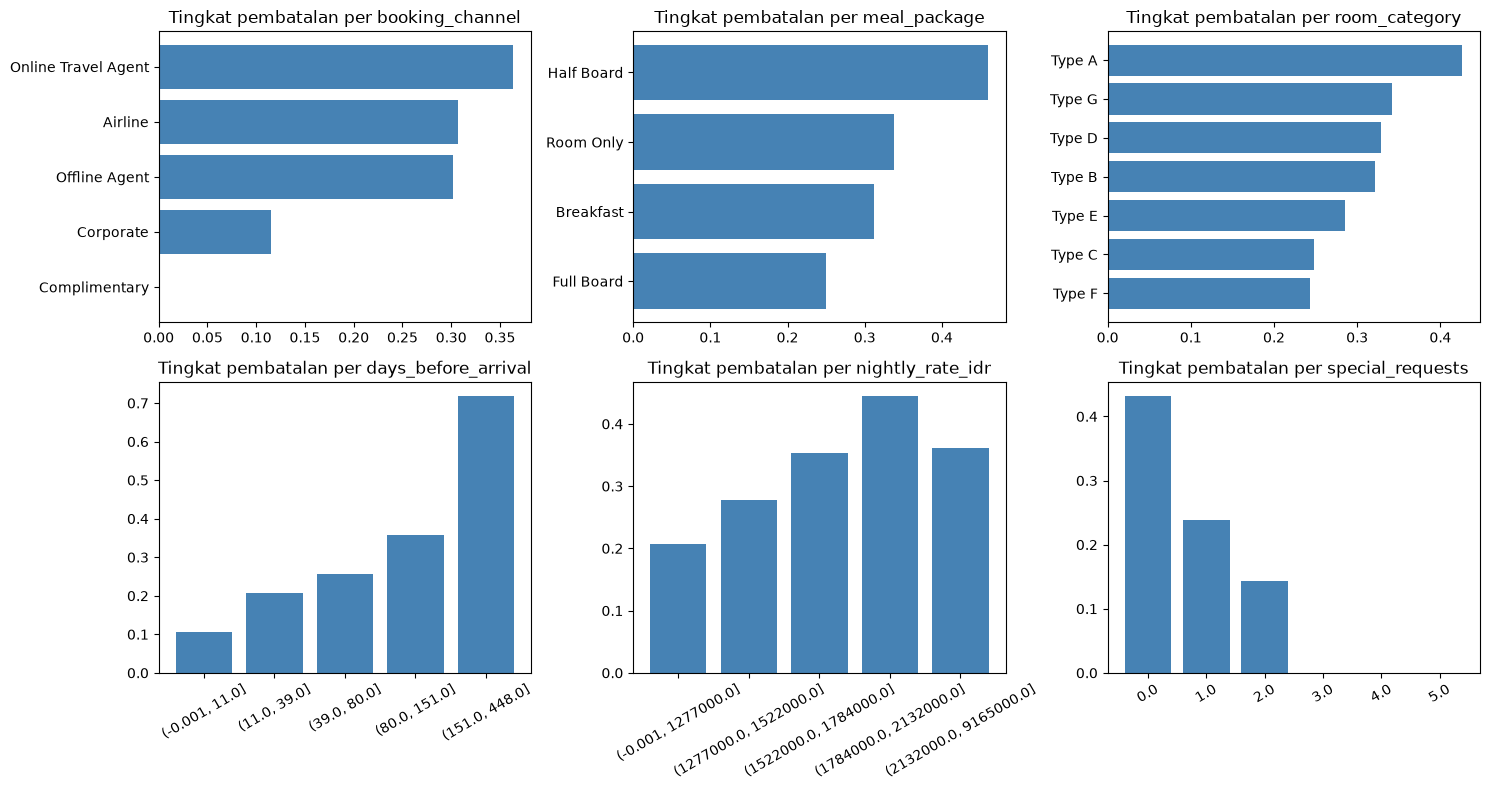

In [7]:
print('Proporsi target:')
print(train_df[TARGET].value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes[0], ['booking_channel', 'meal_package', 'room_category']):
    rate = train_df.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
for ax, col in zip(axes[1], ['days_before_arrival', 'nightly_rate_idr', 'special_requests']):
    if train_df[col].nunique() > 10:
        bins = pd.qcut(train_df[col], 5, duplicates='drop')
    else:
        bins = train_df[col]
    rate = train_df.groupby(bins, observed=True)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Insights:**

- Kelas tidak seimbang secara moderat: sekitar 67% tidak batal, 33% batal.
- `days_before_arrival` adalah sinyal terkuat: pesanan yang dibuat jauh hari lebih sering dibatalkan.
- `special_requests` berbanding terbalik dengan pembatalan; tamu dengan 3 permintaan atau lebih hampir tidak pernah membatalkan.
- Kanal *Complimentary* dan *Corporate* jarang batal, sedangkan *Online Travel Agent* paling sering.
- Pola-pola ini tidak linear, sehingga model seperti KNN dan *decision tree* diperkirakan lebih cocok daripada model linear.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
quality = pd.DataFrame({
    'missing_train': train_df.isna().sum(),
    'missing_test': test_df.isna().sum(),
})
print(quality[quality.sum(axis=1) > 0])

feature_cols = [c for c in train_df.columns if c != 'id']
print('\nBaris duplikat (tanpa id):', train_df.duplicated(subset=feature_cols).sum())
print('Harga 0 (komplimenter):', (train_df['nightly_rate_idr'] == 0).sum())
print('0 orang dewasa:', (train_df['num_adults'] == 0).sum())
print('0 malam menginap:', ((train_df['weekend_nights'] + train_df['weekday_nights']) == 0).sum())
dates = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day), errors='coerce')
print('Tanggal tidak valid:', dates.isna().sum())

                     missing_train  missing_test
days_before_arrival           1123         290.0
meal_package                  1760         442.0
needs_parking                 1082         247.0
nightly_rate_idr              2038         540.0
num_adults                     809         180.0
num_children                  3035         747.0
room_category                 1002         242.0
special_requests              2500         593.0

Baris duplikat (tanpa id): 64
Harga 0 (komplimenter): 413
0 orang dewasa: 106
0 malam menginap: 64
Tanggal tidak valid: 0


**Insights:**

- Delapan kolom memiliki *missing values* sebesar 3–11%, dengan pola serupa di train dan test.
- Terdapat 64 baris duplikat. Duplikat hanya dibuang dari data latih agar validasi tetap mencerminkan data asli.
- Harga 0 sesuai deskripsi dataset (menginap komplimenter), jadi bukan kesalahan data.
- Pesanan dengan 0 orang dewasa atau 0 malam jumlahnya sedikit dan juga muncul di data test, sehingga tetap dipertahankan.
- Semua tanggal kedatangan valid.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
from sklearn.model_selection import train_test_split

train_set, val_set = train_test_split(
    train_df, test_size=CFG.VAL_SIZE, stratify=train_df[TARGET], random_state=CFG.SEED,
)
train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)
print(f'Train: {train_set.shape}  Validation: {val_set.shape}')
print('Proporsi batal  train: %.3f  val: %.3f' % (train_set[TARGET].mean(), val_set[TARGET].mean()))

Train: (21898, 19)  Validation: (5475, 19)
Proporsi batal  train: 0.328  val: 0.328


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
# id hanya penanda baris, sedangkan target dipisahkan saat format data.
selected_features = NUMERIC_COLS + CATEGORICAL_COLS
print(len(selected_features), 'fitur dipakai:', selected_features)

17 fitur dipakai: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package', 'room_category', 'booking_channel']


**Insights:**

Semua 17 fitur asli dipakai. Pada bagian *Eksperimen Pendukung Keputusan Preprocessing* di bawah, hasil membuang tiap fitur dibandingkan dengan semua fitur, sedangkan semua fitur memiliki hubungan yang masuk akal dengan pembatalan.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
print(train_set[selected_features].isna().sum()[lambda s: s > 0])
print('\nMedian (dari data latih) untuk imputasi numerik:')
print(train_set[NUMERIC_COLS].median().to_string())

num_adults              636
num_children           2426
needs_parking           885
days_before_arrival     877
nightly_rate_idr       1622
special_requests       2015
meal_package           1403
room_category           810
dtype: int64

Median (dari data latih) untuk imputasi numerik:
num_adults                        2.0
num_children                      0.0
weekend_nights                    1.0
weekday_nights                    2.0
needs_parking                     0.0
days_before_arrival              57.0
arrival_year                   2024.0
arrival_month                     8.0
arrival_day                      16.0
is_returning_guest                0.0
prior_cancellations               0.0
prior_completed_bookings          0.0
nightly_rate_idr            1647000.0
special_requests                  0.0


**Insights:**

- Numerik: diisi median data latih, karena median tahan terhadap distribusi yang miring seperti `days_before_arrival`.
- Kategorikal: diisi kategori baru `Unknown`, sehingga informasi "tidak diisi" tetap ada.
- Imputasi dikerjakan di dalam `Preprocessor.fit` / `transform` (`src/preprocessing.py`) agar median hanya dihitung dari data latih.

### Duplicates

This part covers repeated records.

In [12]:
n_before = len(train_set)
train_set = drop_duplicate_rows(train_set)
print(f'Duplikat dibuang dari data latih: {n_before - len(train_set)}')

Duplikat dibuang dari data latih: 40


### Outliers

This part covers values far from the rest of the data.

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(train_set[NUMERIC_COLS].apply(iqr_outliers).sort_values(ascending=False).head(8))

num_adults                  5916
arrival_year                3941
num_children                1613
nightly_rate_idr             886
days_before_arrival          750
needs_parking                644
is_returning_guest           545
prior_completed_bookings     477
dtype: int64


**Insights:**

- Pada kolom diskret dengan IQR = 0 (`num_adults`, `arrival_year`, `num_children`, kolom biner), aturan IQR menandai hampir semua nilai selain modus sebagai *outlier*. Aturan ini tidak cocok untuk kolom seperti itu.
- Pada kolom kontinu (`nightly_rate_idr`, `days_before_arrival`, `prior_completed_bookings`), nilai di luar batas IQR adalah nilai yang mungkin terjadi, bukan kesalahan input.
- Karena itu *outlier* dipertahankan. Efeknya pada jarak KNN dikurangi oleh standarisasi dan transformasi log pada lead time.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
# Kolom bilangan bulat yang memiliki NaN terbaca sebagai float. Ini tidak masalah karena semua fitur numerik diproses sebagai float.
for col in CATEGORICAL_COLS:
    print(col, sorted(train_set[col].dropna().unique()))

meal_package ['Breakfast', 'Full Board', 'Half Board', 'Room Only']
room_category ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']
booking_channel ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


**Insights:**

Label kategori konsisten dan tidak ada nilai yang mustahil. Kategori yang sangat jarang (misalnya *Full Board* dengan 4 baris) digabung menjadi `Other` saat *encoding*.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [15]:
pp_demo = Preprocessor().fit(train_set)
derived_preview = Preprocessor._derive(train_set[NUMERIC_COLS].fillna(pp_demo.medians_))
derived_preview.head()

,log_lead_time,arrival_date_ordinal
0,5.963579,739181.0
1,5.726848,739193.0
2,5.117994,738795.0
3,3.401197,739221.0
4,3.332205,739015.0


**Insights:**

- `log_lead_time = log(1 + days_before_arrival)`: lead time sangat miring ke kanan; log membuat jarak antara 0 dan 30 hari lebih berarti daripada jarak antara 300 dan 330 hari.
- `arrival_date_ordinal`: tanggal kedatangan sebagai satu angka, sehingga tren waktu (tingkat batal 2023 jauh lebih rendah daripada 2024) terwakili dalam satu dimensi.
- Kedua fitur ini menaikkan Macro F1 KNN pada *cross-validation*. Fitur turunan lain yang dicoba (total malam, total tamu, harga per tamu, hari dalam minggu) tidak membantu KNN sehingga tidak dipakai.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
print('Mean dan std (dari data latih) untuk standarisasi:')
print(pd.DataFrame({'mean': pp_demo.mean_, 'std': pp_demo.std_}).round(3))

Mean dan std (dari data latih) untuk standarisasi:
                                 mean         std
num_adults                      1.852       0.512
num_children                    0.105       0.407
weekend_nights                  0.818       0.875
weekday_nights                  2.198       1.421
needs_parking                   0.029       0.169
days_before_arrival            83.873      84.245
arrival_year                 2023.820       0.384
arrival_month                   7.395       3.077
arrival_day                    15.540       8.772
is_returning_guest              0.025       0.156
prior_cancellations             0.021       0.357
prior_completed_bookings        0.139       1.627
nightly_rate_idr          1713998.445  563908.889
special_requests                0.608       0.786
log_lead_time                   3.741       1.453
arrival_date_ordinal       739029.164     139.961


**Insights:**

Standarisasi z-score dipakai untuk KNN, karena tanpa *scaling* jarak didominasi `nightly_rate_idr` (jutaan) dan `days_before_arrival` (ratusan). Kolom *one-hot* dibiarkan bernilai 0/1.

### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
for col, cats in pp_demo.categories_.items():
    print(col, '->', cats)

meal_package -> ['Breakfast', 'Half Board', 'Room Only', 'Unknown', 'Other']
room_category -> ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G', 'Unknown', 'Other']
booking_channel -> ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent', 'Other']


**Insights:**

Ketiga fitur kategorikal bersifat nominal (tidak berurutan), jadi dipakai *one-hot encoding*. *Label encoding* akan membuat KNN menganggap, misalnya, Type A lebih dekat ke Type B daripada ke Type G, padahal huruf tersebut tidak memiliki urutan.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
X_demo = pp_demo.transform(train_set)
Xc = X_demo - X_demo.mean(axis=0)
explained = np.linalg.svd(Xc, compute_uv=False) ** 2
explained_ratio = np.cumsum(explained) / explained.sum()
for n in (5, 10, 15, 20):
    print(f'{n} komponen utama menjelaskan {explained_ratio[n - 1]:.1%} variansi')

5 komponen utama menjelaskan 51.0% variansi
10 komponen utama menjelaskan 78.8% variansi
15 komponen utama menjelaskan 94.3% variansi
20 komponen utama menjelaskan 99.0% variansi


**Insights:**

Dengan hanya 35 kolom setelah *encoding*, dimensi masih kecil untuk KNN. PCA juga membutuhkan banyak komponen untuk mempertahankan sebagian besar variansi, sehingga PCA tidak dipakai pada model utama. Perbandingan Macro F1 dengan dan tanpa PCA ada pada bagian *Eksperimen Pendukung Keputusan Preprocessing* di bawah.

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
print(train_set[TARGET].value_counts().to_string())
print(train_set[TARGET].value_counts(normalize=True).round(3).to_string())

is_canceled
0    14696
1     7162
is_canceled
0    0.672
1    0.328


**Insights:**

Rasio sekitar 67:33 tergolong tidak seimbang secara moderat. Tidak dilakukan *resampling*; perbandingan tanpa penanganan, class weight, dan random oversampling ada pada bagian *Eksperimen Pendukung Keputusan Preprocessing* di bawah.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
y_train = train_set[TARGET].to_numpy()
y_val = val_set[TARGET].to_numpy()
print('y_train', y_train.shape, ' y_val', y_val.shape)

y_train (21858,)  y_val (5475,)


## Eksperimen Pendukung Keputusan Preprocessing

Bagian ini memberi bukti untuk keputusan tidak memakai PCA, tidak membuang fitur, dan tidak melakukan *resampling*. Semua statistik dipelajari dari data latih saja dan evaluasi memakai data validasi. Dua model cepat dipakai sebagai alat ukur: Logistic Regression (L2) dan KNN (Euclidean, k = 21, voting 1/jarak) dengan data hasil `Preprocessor` standar. Keputusan dicetak otomatis oleh sel di bawah dan mengikuti aturan: suatu perlakuan dipakai hanya jika Macro F1 validasi naik pada kedua model.

In [21]:
def quick_scores(X_tr, X_va, y_tr=None, class_weight=None):
    y_fit = y_train if y_tr is None else y_tr
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        lr_quick = LogisticRegression(penalty='l2', alpha=1e-3, lr=0.2, max_iter=1000, tol=1e-6,
                                      class_weight=class_weight, seed=CFG.SEED).fit(X_tr, y_fit)
    knn_quick = KNN(k=21, p=2, weights='distance').fit(X_tr, y_fit)
    return {'LogReg': macro_f1(y_val, lr_quick.predict(X_va)),
            'KNN': macro_f1(y_val, knn_quick.predict(X_va))}


exp_prep = Preprocessor(scale=True, min_category_freq=20, add_derived=True).fit(train_set)
X_exp_train = exp_prep.transform(train_set)
X_exp_val = exp_prep.transform(val_set)
exp_baseline = quick_scores(X_exp_train, X_exp_val)
print('Baseline (semua fitur, tanpa PCA, tanpa resampling):', {k: round(v, 4) for k, v in exp_baseline.items()})

Baseline (semua fitur, tanpa PCA, tanpa resampling): {'LogReg': 0.7636, 'KNN': 0.8352}


In [22]:
pca_rows = [{'perlakuan': f'tanpa PCA ({X_exp_train.shape[1]} kolom)', **exp_baseline}]
for n_comp in [25, 20, 15, 10, 5]:
    if n_comp >= X_exp_train.shape[1]:
        continue
    pca_exp = PCA(n_comp).fit(X_exp_train)
    scores = quick_scores(pca_exp.transform(X_exp_train), pca_exp.transform(X_exp_val))
    pca_rows.append({'perlakuan': f'PCA {n_comp} komponen (variansi {pca_exp.explained_variance_ratio_.sum():.1%})', **scores})
pca_table = pd.DataFrame(pca_rows)
print(pca_table.round(4).to_string(index=False))
pca_table.to_csv(CFG.OUTPUT_DIR / 'experiment_pca.csv', index=False)
pca_helps = ((pca_table.loc[1:, 'LogReg'] > exp_baseline['LogReg']) & (pca_table.loc[1:, 'KNN'] > exp_baseline['KNN'])).any()
print('Keputusan PCA:', 'dipakai' if pca_helps else 'tidak dipakai (tidak menaikkan Macro F1 pada kedua model)')

                       perlakuan  LogReg    KNN
            tanpa PCA (35 kolom)  0.7636 0.8352
PCA 25 komponen (variansi 99.9%)  0.7637 0.8355
PCA 20 komponen (variansi 99.0%)  0.7631 0.8339
PCA 15 komponen (variansi 94.3%)  0.7333 0.8236
PCA 10 komponen (variansi 78.8%)  0.7079 0.8080
 PCA 5 komponen (variansi 51.0%)  0.7036 0.7853
Keputusan PCA: dipakai


In [23]:
group_names, group_of_column = feature_groups(exp_prep)
fs_rows = []
for g, group in enumerate(group_names):
    keep = group_of_column != g
    scores = quick_scores(X_exp_train[:, keep], X_exp_val[:, keep])
    fs_rows.append({'fitur dibuang': group, **scores,
                    'selisih LogReg': scores['LogReg'] - exp_baseline['LogReg'],
                    'selisih KNN': scores['KNN'] - exp_baseline['KNN']})
fs_table = pd.DataFrame(fs_rows).sort_values('selisih KNN', ascending=False).reset_index(drop=True)
print(fs_table.round(4).to_string(index=False))
fs_table.to_csv(CFG.OUTPUT_DIR / 'experiment_feature_selection.csv', index=False)
fs_helps = fs_table[(fs_table['selisih LogReg'] > 0) & (fs_table['selisih KNN'] > 0)]['fitur dibuang'].tolist()
print('Keputusan feature selection:', f'fitur yang layak dibuang: {fs_helps}' if fs_helps else 'semua fitur dipakai (tidak ada fitur yang jika dibuang menaikkan Macro F1 pada kedua model)')

           fitur dibuang  LogReg    KNN  selisih LogReg  selisih KNN
            meal_package  0.7592 0.8390         -0.0045       0.0038
           room_category  0.7622 0.8369         -0.0015       0.0017
            num_children  0.7644 0.8368          0.0008       0.0016
             arrival_day  0.7647 0.8359          0.0010       0.0007
          weekday_nights  0.7624 0.8358         -0.0013       0.0006
           arrival_month  0.7632 0.8357         -0.0004       0.0005
            arrival_year  0.7636 0.8357          0.0000       0.0005
    arrival_date_ordinal  0.7636 0.8352          0.0000       0.0001
     prior_cancellations  0.7631 0.8352         -0.0005       0.0000
prior_completed_bookings  0.7636 0.8352          0.0000       0.0000
          weekend_nights  0.7619 0.8351         -0.0017      -0.0001
      is_returning_guest  0.7638 0.8349          0.0002      -0.0003
              num_adults  0.7634 0.8337         -0.0003      -0.0015
           needs_parking  0.7633 0

In [24]:
rng_bal = np.random.default_rng(CFG.SEED)
minority = np.flatnonzero(y_train == 1)
majority = np.flatnonzero(y_train == 0)
extra = rng_bal.choice(minority, size=len(majority) - len(minority), replace=True)
over_idx = np.concatenate([np.arange(len(y_train)), extra])
bal_rows = [
    {'perlakuan': 'tanpa penanganan', **exp_baseline},
    {'perlakuan': 'class weight balanced (LogReg saja)',
     'LogReg': quick_scores(X_exp_train, X_exp_val, class_weight='balanced')['LogReg'], 'KNN': np.nan},
    {'perlakuan': 'random oversampling kelas batal (data latih)',
     **quick_scores(X_exp_train[over_idx], X_exp_val, y_tr=y_train[over_idx])},
]
bal_table = pd.DataFrame(bal_rows)
print(bal_table.round(4).to_string(index=False))
bal_table.to_csv(CFG.OUTPUT_DIR / 'experiment_class_balance.csv', index=False)
resampling_helps = bool((bal_table.loc[2, 'LogReg'] > exp_baseline['LogReg']) and (bal_table.loc[2, 'KNN'] > exp_baseline['KNN']))
print('Keputusan resampling:', 'dipakai' if resampling_helps else 'tidak dipakai (tidak menaikkan Macro F1 pada kedua model)')

                                   perlakuan  LogReg    KNN
                            tanpa penanganan  0.7636 0.8352
         class weight balanced (LogReg saja)  0.7499    NaN
random oversampling kelas batal (data latih)  0.7503 0.8159
Keputusan resampling: tidak dipakai (tidak menaikkan Macro F1 pada kedua model)


**Catatan:** keputusan di notebook ini (tanpa PCA, semua fitur, tanpa *resampling*) harus sama dengan keluaran sel di atas. Jika salah satu sel mencetak keputusan berbeda, perbarui bagian *Insights* terkait dan laporan sebelum pengumpulan.

---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

### Ringkasan Preprocessing per Model

Semua model memakai tahap yang sama: `drop_duplicate_rows` pada data latih, pemisahan latih/validasi sebelum preprocessing, dan statistik yang dipelajari dari data latih saja. Perbedaan antarmodel dijaga sekecil mungkin dan setiap perbedaan memiliki alasan.

| Model | Preprocessing | Alasan perbedaan |
|---|---|---|
| KNN | `Preprocessor`: imputasi median / "Unknown", fitur turunan, one-hot, standarisasi, bobot fitur hasil pencarian | Jarak sensitif terhadap skala; bobot fitur adalah bagian optimasi KNN |
| Logistic Regression | `Preprocessor` yang sama tanpa bobot fitur | Gradient descent sensitif terhadap skala |
| SVM | `Preprocessor` yang sama tanpa bobot fitur | Kernel berbasis jarak dan dot product sensitif terhadap skala; varian `SVMPreprocessor` hanya dipakai pada optimasi bonus |
| DTL (C4.5) | Data mentah, tanpa imputasi, one-hot, dan scaling | Pohon menangani numerik, kategorikal, dan nilai kosong sendiri, dan tidak peka terhadap skala |
| Naive Bayes | `NaiveBayesPreprocessor`: imputasi median, diskretisasi kuantil dari data latih, kode kategori | Sesuai QnA, slide Bayes Net hanya membahas atribut kategorikal sehingga atribut numerik harus didiskretisasi |

Pembanding scikit-learn memakai data yang sama dengan model *from scratch* masing-masing, kecuali `DecisionTreeClassifier` yang tidak menerima kategori teks sehingga memakai `Preprocessor(scale=False)` (one-hot tanpa scaling).

In [25]:
preprocessor = Preprocessor(scale=True, min_category_freq=20, add_derived=True)
X_train = preprocessor.fit_transform(train_set)   # Fit hanya pada data latih.
X_val = preprocessor.transform(val_set)           # Validasi hanya ditransformasi.

print('X_train', X_train.shape, ' X_val', X_val.shape)
print('NaN tersisa:', np.isnan(X_train).sum(), np.isnan(X_val).sum())
print(preprocessor.feature_names_)

X_train (21858, 35)  X_val (5475, 35)
NaN tersisa: 0 0
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'log_lead_time', 'arrival_date_ordinal', 'meal_package=Breakfast', 'meal_package=Half Board', 'meal_package=Room Only', 'meal_package=Unknown', 'meal_package=Other', 'room_category=Type A', 'room_category=Type B', 'room_category=Type C', 'room_category=Type D', 'room_category=Type F', 'room_category=Type G', 'room_category=Unknown', 'room_category=Other', 'booking_channel=Airline', 'booking_channel=Complimentary', 'booking_channel=Corporate', 'booking_channel=Offline Agent', 'booking_channel=Online Travel Agent', 'booking_channel=Other']


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

Implementasi: `src/knn.py` (kelas `KNN`). Jarak Euclidean, Manhattan, atau Minkowski; voting seragam atau berbobot `1/jarak^power` (`power` = 1 atau 2); komputasi jarak per *batch* agar memori terkendali. Bobot fitur pada jarak diterapkan di `Preprocessor(feature_weights=...)` dan dioptimasi dengan `FeatureWeightSearch` (`src/knn_weight_search.py`).

In [26]:
# Tuning hyperparameter dengan stratified 5-fold CV pada data latih.
# Preprocessor di-fit ulang di setiap fold supaya fold validasi tidak bocor.
K_GRID = [5, 11, 15, 21, 31, 41, 61]
P_GRID = [1, 2]   # 1 = Manhattan, 2 = Euclidean
# Jenis voting dan pangkat jarak: seragam, 1/jarak, dan 1/jarak^2.
W_GRID = [('uniform', 1.0), ('distance', 1.0), ('distance', 2.0)]
FW_GRID = {'none': None, 'weighted': CFG.FEATURE_WEIGHTS}
FOLDS = list(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED))

cv_scores = {}
start = time.time()
for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    for fw_name, fw in FW_GRID.items():
        pp = Preprocessor(feature_weights=fw).fit(fold_tr)
        Xf_tr, Xf_va = pp.transform(fold_tr), pp.transform(fold_va)
        for p in P_GRID:
            # Tetangga dicari sekali dengan k terbesar, k yang lebih kecil cukup memotong hasilnya.
            searcher = KNN(k=max(K_GRID), p=p).fit(Xf_tr, y_train[tr_idx])
            dist, idx = searcher.kneighbors(Xf_va)
            for w, power in W_GRID:
                searcher.weights, searcher.power = w, power
                for k in K_GRID:
                    pred = searcher.predict_from_neighbors(dist, idx, k)
                    cv_scores.setdefault((fw_name, k, p, w, power), []).append(macro_f1(y_train[va_idx], pred))
    print(f'fold {fold + 1} selesai ({time.time() - start:.0f} s)')

cv_table = (pd.DataFrame([(fw, k, p, w, power, np.mean(s), np.std(s), s)
                          for (fw, k, p, w, power), s in cv_scores.items()],
                         columns=['feature_weights', 'k', 'p', 'weights', 'power', 'cv_macro_f1', 'std', 'fold_scores'])
            .sort_values('cv_macro_f1', ascending=False, kind='stable').reset_index(drop=True))
cv_table.drop(columns='fold_scores').head(10)

fold 1 selesai (48 s)
fold 2 selesai (97 s)
fold 3 selesai (152 s)
fold 4 selesai (213 s)
fold 5 selesai (324 s)


,feature_weights,k,p,weights,power,cv_macro_f1,std
0,weighted,31,1,distance,2.0,0.846508,0.004881
1,weighted,41,1,distance,2.0,0.846208,0.004475
2,weighted,61,1,distance,2.0,0.844934,0.004539
3,weighted,21,1,distance,2.0,0.844873,0.003390
4,weighted,15,1,distance,2.0,0.842368,0.002625
5,weighted,21,1,distance,1.0,0.842070,0.003191
6,weighted,11,1,distance,1.0,0.840809,0.003037
7,weighted,11,1,distance,2.0,0.840746,0.002063
8,weighted,15,1,distance,1.0,0.840287,0.003150
9,weighted,31,1,distance,1.0,0.840049,0.003084


**Insights:**

- Jarak Manhattan (`p=1`) konsisten lebih baik daripada Euclidean. Manhattan tidak mengkuadratkan selisih, sehingga satu fitur yang sangat berbeda tidak mendominasi jarak.
- Voting `1/jarak^2` lebih baik daripada `1/jarak` dan `uniform`. Dengan pangkat 2, tetangga yang sangat dekat jauh lebih menentukan, sedangkan tetangga yang lebih jauh tetap bersuara dengan bobot kecil.
- Dengan `1/jarak^2`, k terbaik bergeser ke 31 (CV 0,8465), lebih besar daripada k = 21 pada voting `1/jarak` (CV 0,8421). Tambahan tetangga jauh tidak banyak menambah *noise* karena bobotnya cepat mengecil.
- Selisih k = 31 dan k = 41 hanya 0,0003, jauh lebih kecil daripada simpangan antar-fold (sekitar 0,005), sehingga keduanya setara. k = 31 dipilih karena CV-nya tertinggi.
- Jarak berbobot fitur (`weighted`) lebih baik daripada tanpa bobot pada konfigurasi yang sama (lihat perbandingan per fold di bawah).

In [27]:
best = cv_table.iloc[0]
BEST_FW_NAME, BEST_K, BEST_P, BEST_W = best.feature_weights, int(best.k), int(best.p), best.weights
BEST_POWER = float(best.power)
BEST_FW = FW_GRID[BEST_FW_NAME]
print(f'Hyperparameter terbaik: feature_weights={BEST_FW_NAME}, k={BEST_K}, p={BEST_P}, weights={BEST_W}, '
      f'power={BEST_POWER:g}  (CV macro F1 = {best.cv_macro_f1:.4f})')

# Bandingkan jarak berbobot dan tanpa bobot pada fold yang sama.
def pick(fw):
    q = cv_table.query('feature_weights == @fw and k == @BEST_K and p == @BEST_P '
                       'and weights == @BEST_W and power == @BEST_POWER')
    return q.iloc[0]

a, b = np.array(pick('weighted').fold_scores), np.array(pick('none').fold_scores)
print(f'Berbobot vs tanpa bobot (k={BEST_K}, p={BEST_P}, {BEST_W}, power={BEST_POWER:g}): '
      f'selisih rata-rata {np.mean(a - b):+.4f}, berbobot menang di {np.sum(a > b)}/{len(a)} fold')

# Model dengan bobot awal pada seluruh data latih, sebagai pembanding optimasi bobot di bawah.
initial_prep = Preprocessor(feature_weights=BEST_FW).fit(train_set)
knn_initial = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(initial_prep.transform(train_set), y_train)
start = time.time()
knn_initial_val_pred = knn_initial.predict(initial_prep.transform(val_set))
print(f'Waktu prediksi validasi: {time.time() - start:.1f} s')
print(f'Validation macro F1 (bobot awal) = {macro_f1(y_val, knn_initial_val_pred):.4f}   '
      f'accuracy = {accuracy(y_val, knn_initial_val_pred):.4f}')

Hyperparameter terbaik: feature_weights=weighted, k=31, p=1, weights=distance, power=2  (CV macro F1 = 0.8465)
Berbobot vs tanpa bobot (k=31, p=1, distance, power=2): selisih rata-rata +0.0088, berbobot menang di 5/5 fold
Waktu prediksi validasi: 70.5 s
Validation macro F1 (bobot awal) = 0.8501   accuracy = 0.8698


### Optimasi bobot fitur KNN

Bobot awal `CFG.FEATURE_WEIGHTS` ditemukan ketika KNN masih memakai voting `1/jarak` dengan k = 21. Voting terbaik sekarang adalah `1/jarak^2` dengan k yang lebih besar, sehingga bobot fitur dicari ulang dengan *coordinate search* (`FeatureWeightSearch` di `src/knn_weight_search.py`):

1. Untuk setiap baris fold validasi disimpan `CFG.KNN_CANDIDATES` = 150 kandidat tetangga terdekat menurut bobot awal, beserta selisih setiap fiturnya.
2. Bobot setiap fitur dicoba bergantian dengan nilai dari `CFG.KNN_WEIGHT_GRID`. Jarak cukup dihitung ulang dari selisih yang tersimpan, lalu k tetangga terdekat dipilih dari kandidat tersebut.
3. Bobot baru diterima hanya jika Macro F1 *cross-validation* naik lebih dari 0,0005. Putaran diulang sampai tidak ada bobot yang berubah.

Fold yang dipakai sama dengan tuning di atas dan seluruhnya berasal dari data latih. Data validasi 20% hanya dipakai untuk memeriksa hasil akhir.

Referensi: D. Wettschereck, D. W. Aha, dan T. Mohri, "A Review and Empirical Evaluation of Feature Weighting Methods for a Class of Lazy Learning Algorithms", *Artificial Intelligence Review* 11, 1997; R. Kohavi dan G. H. John, "Wrappers for Feature Subset Selection", *Artificial Intelligence* 97, 1997.

In [28]:
# Pencarian ulang bobot fitur dengan k dan voting terbaik dari tuning di atas.
start = time.time()
weight_search = FeatureWeightSearch(k=BEST_K, power=BEST_POWER, grid=CFG.KNN_WEIGHT_GRID,
                                    n_candidates=CFG.KNN_CANDIDATES).fit(train_set, y_train, FOLDS, BEST_FW or {})
print(f'Waktu pencarian: {time.time() - start:.0f} s')
print(f'CV macro F1: {weight_search.initial_score_:.4f} (bobot awal) -> {weight_search.cv_score_:.4f} (bobot akhir)')
FINAL_FW = {f: w for f, w in weight_search.weights_.items() if w != 1.0}
print('Bobot akhir (fitur lain bernilai 1):', FINAL_FW)

# Model validasi dengan bobot akhir. Preprocessor dan KNN ini dipakai di bagian-bagian berikutnya.
preprocessor = Preprocessor(feature_weights=FINAL_FW)
X_train = preprocessor.fit_transform(train_set)
X_val = preprocessor.transform(val_set)
knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(X_train, y_train)
knn_val_pred = knn.predict(X_val)
print(f'Validation macro F1 = {macro_f1(y_val, knn_val_pred):.4f} (bobot awal {macro_f1(y_val, knn_initial_val_pred):.4f})   '
      f'accuracy = {accuracy(y_val, knn_val_pred):.4f}')
weight_search.history_

Waktu pencarian: 309 s
CV macro F1: 0.8465 (bobot awal) -> 0.8494 (bobot akhir)
Bobot akhir (fitur lain bernilai 1): {'num_adults': 0.75, 'num_children': 0.0, 'weekend_nights': 0.75, 'days_before_arrival': 1.5, 'nightly_rate_idr': 1.5, 'special_requests': 1.5, 'log_lead_time': 1.5, 'meal_package': 0.5, 'room_category': 0.5}
Validation macro F1 = 0.8541 (bobot awal 0.8501)   accuracy = 0.8732


,putaran,fitur,bobot_lama,bobot_baru,cv_macro_f1
0,0,(bobot awal),NaN,NaN,0.846518
1,1,num_adults,1.0,0.75,0.847578
2,1,num_children,1.0,0.00,0.848741
3,1,weekend_nights,1.0,0.75,0.849435


**Insights:**

- *Coordinate search* mengubah tiga bobot: `num_children` menjadi 0, serta `num_adults` dan `weekend_nights` menjadi 0,75. Macro F1 CV naik dari 0,8465 menjadi 0,8494.
- Macro F1 validasi naik dari 0,8501 menjadi 0,8541, dan akurasinya dari 0,8698 menjadi 0,8732. Data validasi tidak dipakai saat pencarian, sehingga kenaikan ini bukan hasil *overfitting* terhadap data validasi.
- `num_children` memiliki *missing values* terbanyak (11%) yang diisi median 0, dan hampir semua pesanan tidak membawa anak. Selisih pada kolom ini lebih banyak menambah *noise* pada jarak daripada informasi, sehingga bobot 0 (fitur tidak dipakai dalam jarak) lebih baik.
- Jumlah dewasa dan malam akhir pekan tetap dipakai, tetapi pengaruhnya pada jarak dikurangi agar tetangga lebih ditentukan oleh lead time, harga, dan jumlah permintaan khusus.

## Decision Tree Learning

Varian yang dipilih adalah **C4.5** (`src/dtl.py`, kelas `DecisionTree`), dengan ketentuan berikut:

- **Kriteria pemisahan:** *gain ratio*. Atribut numerik memakai threshold biner (titik tengah antar nilai berurutan, dengan koreksi Quinlan), atribut kategorikal memakai pemisahan multi-cabang.
- **Missing values** ditangani langsung oleh pohon. Saat latih, sampel yang nilainya kosong dibagi ke semua cabang dengan bobot pecahan. Saat prediksi, probabilitas kelas dari semua cabang dijumlahkan dengan bobot yang sama.
- **Pemangkasan:** pra-pangkas (`max_depth`, `min_samples_leaf`) dan pasca-pangkas *cost-complexity* (`ccp_alpha`, berbasis entropi).
- **Preprocessing berbeda dari model lain:** DTL memakai data mentah (`NUMERIC_COLS + CATEGORICAL_COLS`) tanpa imputasi, *one-hot*, dan *scaling*, karena pohon menangani numerik, kategorikal, dan nilai kosong sendiri dan tidak peka terhadap skala. Duplikat sudah dibuang pada tahap *cleaning* yang sama dengan model lain (sesuai QnA: perbedaan preprocessing sekecil mungkin dan harus dijustifikasi).

Hyperparameter dipilih dengan *stratified 5-fold cross-validation* pada data latih.

In [29]:
RAW_FEATURES = NUMERIC_COLS + CATEGORICAL_COLS
DTL_DEPTHS = [8, 12, 16]
DTL_MIN_LEAF = [3, 10]
DTL_CCP_GRID = [0.0, 0.0002, 0.0005, 0.001, 0.002]
dtl_folds = list(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED))


def dtl_cv_score(params):
    scores = []
    for tr_idx, va_idx in dtl_folds:
        model = DecisionTree(**params).fit(train_set.iloc[tr_idx][RAW_FEATURES], y_train[tr_idx])
        pred = model.predict(train_set.iloc[va_idx][RAW_FEATURES])
        scores.append(macro_f1(y_train[va_idx], pred))
    return float(np.mean(scores)), float(np.std(scores))


dtl_start = time.perf_counter()
dtl_rows = []
for depth in DTL_DEPTHS:
    for leaf in DTL_MIN_LEAF:
        mean, std = dtl_cv_score(dict(max_depth=depth, min_samples_leaf=leaf))
        dtl_rows.append({'max_depth': depth, 'min_samples_leaf': leaf, 'ccp_alpha': 0.0,
                         'cv_macro_f1': mean, 'cv_std': std})
        print(f'depth={depth} leaf={leaf}: CV Macro F1 = {mean:.4f} +- {std:.4f}', flush=True)
dtl_cv_table = pd.DataFrame(dtl_rows).sort_values('cv_macro_f1', ascending=False, kind='stable').reset_index(drop=True)
DTL_BEST_DEPTH = int(dtl_cv_table.loc[0, 'max_depth'])
DTL_BEST_LEAF = int(dtl_cv_table.loc[0, 'min_samples_leaf'])

ccp_rows = []
for alpha in DTL_CCP_GRID:
    mean, std = dtl_cv_score(dict(max_depth=DTL_BEST_DEPTH, min_samples_leaf=DTL_BEST_LEAF, ccp_alpha=alpha))
    ccp_rows.append({'ccp_alpha': alpha, 'cv_macro_f1': mean, 'cv_std': std})
    print(f'ccp_alpha={alpha}: CV Macro F1 = {mean:.4f} +- {std:.4f}', flush=True)
dtl_ccp_table = pd.DataFrame(ccp_rows)
DTL_BEST_CCP = float(dtl_ccp_table.loc[dtl_ccp_table['cv_macro_f1'].idxmax(), 'ccp_alpha'])
DTL_BEST_PARAMS = dict(max_depth=DTL_BEST_DEPTH, min_samples_leaf=DTL_BEST_LEAF, ccp_alpha=DTL_BEST_CCP)
print('Parameter terpilih:', DTL_BEST_PARAMS)
print(f'Waktu tuning DTL: {time.perf_counter() - dtl_start:.1f} s')
dtl_cv_table.to_csv(CFG.OUTPUT_DIR / 'dtl_cv.csv', index=False)
dtl_cv_table

depth=8 leaf=3: CV Macro F1 = 0.8025 +- 0.0046
depth=8 leaf=10: CV Macro F1 = 0.8009 +- 0.0046
depth=12 leaf=3: CV Macro F1 = 0.8228 +- 0.0025
depth=12 leaf=10: CV Macro F1 = 0.8173 +- 0.0028
depth=16 leaf=3: CV Macro F1 = 0.8228 +- 0.0049
depth=16 leaf=10: CV Macro F1 = 0.8157 +- 0.0021
ccp_alpha=0.0: CV Macro F1 = 0.8228 +- 0.0049
ccp_alpha=0.0002: CV Macro F1 = 0.8224 +- 0.0025
ccp_alpha=0.0005: CV Macro F1 = 0.8172 +- 0.0032
ccp_alpha=0.001: CV Macro F1 = 0.8025 +- 0.0038
ccp_alpha=0.002: CV Macro F1 = 0.7873 +- 0.0086
Parameter terpilih: {'max_depth': 16, 'min_samples_leaf': 3, 'ccp_alpha': 0.0}
Waktu tuning DTL: 358.1 s


,max_depth,min_samples_leaf,ccp_alpha,cv_macro_f1,cv_std
0,16,3,0.0,0.822830,0.004933
1,12,3,0.0,0.822830,0.002518
2,12,10,0.0,0.817270,0.002785
3,16,10,0.0,0.815747,0.002087
4,8,3,0.0,0.802534,0.004592
5,8,10,0.0,0.800874,0.004604


In [30]:
dtl = DecisionTree(**DTL_BEST_PARAMS).fit(train_set[RAW_FEATURES], y_train)
dtl_val_pred = dtl.predict(val_set[RAW_FEATURES])
dtl_results = pd.DataFrame([{
    'model': f"DTL C4.5 (depth<={DTL_BEST_DEPTH}, leaf>={DTL_BEST_LEAF}, ccp_alpha={DTL_BEST_CCP:g})",
    'val_macro_f1': macro_f1(y_val, dtl_val_pred),
    'val_accuracy': accuracy(y_val, dtl_val_pred),
}])
print(f'Kedalaman pohon: {dtl.get_depth()}, jumlah daun: {dtl.get_n_leaves()}')
importance = pd.Series(dtl.feature_importances_, index=dtl.feature_names_).sort_values(ascending=False)
print(importance.head(8).round(4).to_string())
dtl_results

Kedalaman pohon: 16, jumlah daun: 1221
days_before_arrival    0.3464
special_requests       0.1320
booking_channel        0.1309
arrival_month          0.0849
nightly_rate_idr       0.0643
weekend_nights         0.0450
arrival_year           0.0403
weekday_nights         0.0340


,model,val_macro_f1,val_accuracy
0,"DTL C4.5 (depth<=16, leaf>=3, ccp_alpha=0)",0.83329,0.857352


## Logistic Regression

Kelas `LogisticRegression` pada `src/logreg.py` meminimalkan log-loss ditambah penalti dengan *gradient descent* (varian yang diajarkan di kelas):

$$J(\theta) = \frac{1}{n}\sum_i \text{logloss}_i + \alpha\left(r\,\lVert w\rVert_1 + \frac{1-r}{2}\lVert w\rVert_2^2\right)$$

- **L1:** $r=1$. Pembaruan memakai *proximal step* (soft-thresholding), sehingga koefisien benar-benar menjadi nol.
- **L2:** $r=0$.
- **Elastic Net:** $0<r<1$ (di sini $r=0{,}5$).
- Intercept tidak dipenalti. Hubungan dengan scikit-learn: $\alpha = 1/(C\,n)$.

Model ini memakai preprocessing yang sama dengan SVM (*one-hot* dan *z-score*), karena gradien sensitif terhadap skala fitur. Pemilihan penalti dan $\alpha$ memakai *stratified 5-fold CV* dengan preprocessor di-fit ulang pada setiap fold.

In [31]:
import warnings

lr_preprocessor = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=None)
X_lr_train = lr_preprocessor.fit_transform(train_set)
X_lr_val = lr_preprocessor.transform(val_set)
assert np.isfinite(X_lr_train).all() and np.isfinite(X_lr_val).all()

LR_ALPHAS = [1e-4, 1e-3, 1e-2]
LR_PENALTIES = ['l1', 'l2', 'elasticnet']
LR_PARAMS = dict(lr=0.2, max_iter=1000, tol=1e-6, l1_ratio=0.5, seed=CFG.SEED)

lr_fold_data = []
for tr_idx, va_idx in dtl_folds:
    pp = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=None).fit(train_set.iloc[tr_idx])
    lr_fold_data.append((pp.transform(train_set.iloc[tr_idx]), pp.transform(train_set.iloc[va_idx]), tr_idx, va_idx))

lr_start = time.perf_counter()
lr_cv_rows = []
for penalty in LR_PENALTIES:
    for alpha in LR_ALPHAS:
        scores = []
        for Xtr, Xva, tr_idx, va_idx in lr_fold_data:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                model = LogisticRegression(penalty=penalty, alpha=alpha, **LR_PARAMS).fit(Xtr, y_train[tr_idx])
            scores.append(macro_f1(y_train[va_idx], model.predict(Xva)))
        lr_cv_rows.append({'penalty': penalty, 'alpha': alpha, 'cv_macro_f1': np.mean(scores), 'cv_std': np.std(scores)})
        print(f'{penalty} alpha={alpha:g}: CV Macro F1 = {np.mean(scores):.4f} +- {np.std(scores):.4f}', flush=True)
lr_cv_table = pd.DataFrame(lr_cv_rows).sort_values('cv_macro_f1', ascending=False, kind='stable').reset_index(drop=True)
print(f'Waktu tuning LogReg: {time.perf_counter() - lr_start:.1f} s')
lr_cv_table.to_csv(CFG.OUTPUT_DIR / 'logreg_cv.csv', index=False)
lr_cv_table

l1 alpha=0.0001: CV Macro F1 = 0.7631 +- 0.0052
l1 alpha=0.001: CV Macro F1 = 0.7615 +- 0.0059
l1 alpha=0.01: CV Macro F1 = 0.7520 +- 0.0037
l2 alpha=0.0001: CV Macro F1 = 0.7633 +- 0.0052
l2 alpha=0.001: CV Macro F1 = 0.7629 +- 0.0049
l2 alpha=0.01: CV Macro F1 = 0.7585 +- 0.0054
elasticnet alpha=0.0001: CV Macro F1 = 0.7631 +- 0.0052
elasticnet alpha=0.001: CV Macro F1 = 0.7620 +- 0.0050
elasticnet alpha=0.01: CV Macro F1 = 0.7567 +- 0.0032
Waktu tuning LogReg: 448.2 s


,penalty,alpha,cv_macro_f1,cv_std
0,l2,0.0001,0.763348,0.005244
1,elasticnet,0.0001,0.763107,0.005195
2,l1,0.0001,0.763086,0.005210
3,l2,0.0010,0.762937,0.004938
4,elasticnet,0.0010,0.762037,0.005015
5,l1,0.0010,0.761450,0.005892
6,l2,0.0100,0.758482,0.005350
7,elasticnet,0.0100,0.756738,0.003230
8,l1,0.0100,0.752042,0.003741


In [32]:
lr_best_alpha = {p: float(lr_cv_table[lr_cv_table['penalty'] == p].iloc[0]['alpha']) for p in LR_PENALTIES}
LR_BEST_PENALTY = str(lr_cv_table.loc[0, 'penalty'])
LR_BEST_ALPHA = float(lr_cv_table.loc[0, 'alpha'])

lr_models, lr_val_predictions, lr_rows = {}, {}, []
for penalty in LR_PENALTIES:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        model = LogisticRegression(penalty=penalty, alpha=lr_best_alpha[penalty], **LR_PARAMS).fit(X_lr_train, y_train)
    pred = model.predict(X_lr_val)
    lr_models[penalty], lr_val_predictions[penalty] = model, pred
    lr_rows.append({
        'penalty': penalty, 'alpha': lr_best_alpha[penalty],
        'val_macro_f1': macro_f1(y_val, pred), 'val_accuracy': accuracy(y_val, pred),
        'koefisien_nol': int((model.coef_ == 0).sum()), 'iterasi': model.n_iter_,
        'konvergen': bool(model.converged_),
    })
lr_results = pd.DataFrame(lr_rows)
logreg = lr_models[LR_BEST_PENALTY]
logreg_val_pred = lr_val_predictions[LR_BEST_PENALTY]
print('Penalti terbaik (CV):', LR_BEST_PENALTY, 'alpha =', LR_BEST_ALPHA)
lr_results

Penalti terbaik (CV): l2 alpha = 0.0001


,penalty,alpha,val_macro_f1,val_accuracy,koefisien_nol,iterasi,konvergen
0,l1,0.0001,0.762847,0.798539,3,732,True
1,l2,0.0001,0.763277,0.798904,1,745,True
2,elasticnet,0.0001,0.763022,0.798721,3,737,True


             lr  iterasi  konvergen  objective_akhir  val_macro_f1     detik
optimizer                                                                   
gd         0.20      745       True          0.43354       0.76328  12.03570
adam       0.05      122       True          0.43262       0.76343   1.29199


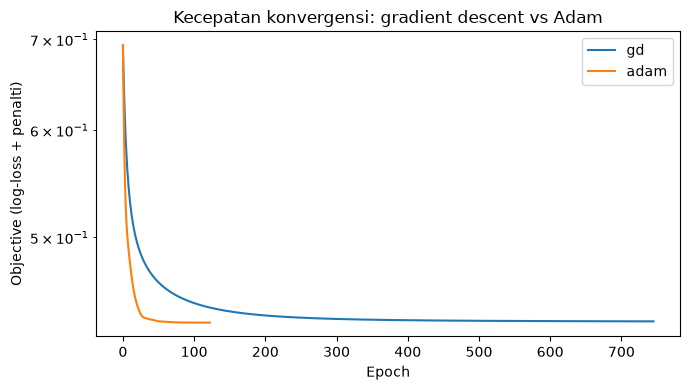

In [33]:
adam_rows, adam_models = [], {}
for optimizer, lr_rate in [('gd', LR_PARAMS['lr']), ('adam', 0.05)]:
    params = dict(LR_PARAMS, lr=lr_rate)
    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        model = LogisticRegression(penalty=LR_BEST_PENALTY, alpha=LR_BEST_ALPHA, optimizer=optimizer, **params).fit(X_lr_train, y_train)
    seconds = time.perf_counter() - start
    adam_models[optimizer] = model
    pred = model.predict(X_lr_val)
    adam_rows.append({'optimizer': optimizer, 'lr': lr_rate, 'iterasi': model.n_iter_, 'konvergen': bool(model.converged_),
                      'objective_akhir': model.loss_history_[-1], 'val_macro_f1': macro_f1(y_val, pred), 'detik': seconds})
adam_table = pd.DataFrame(adam_rows).set_index('optimizer')
print(adam_table.round(5).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for optimizer, model in adam_models.items():
    ax.plot(model.loss_history_, label=optimizer)
ax.set_xlabel('Epoch')
ax.set_ylabel('Objective (log-loss + penalti)')
ax.set_yscale('log')
ax.set_title('Kecepatan konvergensi: gradient descent vs Adam')
ax.legend()
plt.tight_layout()
plt.show()

### Optimasi Logistic Regression dengan Adam (Bonus)

*Gradient descent* memakai satu laju belajar untuk semua koefisien, sehingga lambat ketika skala gradien antar fitur berbeda. **Adam** (Kingma dan Ba, 2015) menyimpan rata-rata bergerak gradien dan kuadrat gradien, lalu mengatur langkah setiap koefisien secara terpisah. Pada penalti L1, soft-thresholding memakai langkah per-koefisien yang sama (pendekatan proximal; lihat Beck dan Teboulle, 2009). Sel di atas membandingkan kedua optimizer pada penalti dan $\alpha$ terbaik: jumlah iterasi, objective akhir, dan Macro F1 validasi.

Referensi:
- D. P. Kingma dan J. Ba, "Adam: A Method for Stochastic Optimization," ICLR, 2015 (arXiv:1412.6980).
- A. Beck dan M. Teboulle, "A Fast Iterative Shrinkage-Thresholding Algorithm for Linear Inverse Problems," SIAM Journal on Imaging Sciences 2(1), 2009.

## Support Vector Machine

SVM mencari batas pemisah dengan margin yang lebar. Parameter C menentukan penalti pelanggaran margin. Implementasi `svm.py` memakai SMO untuk memperbarui dua alpha pada setiap langkah, mengacu pada [Platt (1998)](https://www.microsoft.com/en-us/research/wp-content/uploads/2016/02/tr-98-14.pdf) dan [Fan dkk. (2005)](https://www.jmlr.org/papers/v6/fan05a.html).

Kernel linear, polynomial, dan Gaussian menggunakan data serta preprocessing yang sama. Preprocessing dipelajari dari data latih lalu diterapkan pada validasi. Parameter awalnya C=1, degree=2 untuk polynomial, gamma=1/jumlah fitur, dan toleransi 0,001. Bagian ini memakai parameter awal. Pencarian parameter dilakukan pada bagian optimasi SVM.


In [34]:
svm_preprocessor = Preprocessor(scale=True, min_category_freq=20,
                                add_derived=True, feature_weights=None)
X_svm_train = svm_preprocessor.fit_transform(train_set)
X_svm_val = svm_preprocessor.transform(val_set)
assert np.isfinite(X_svm_train).all() and np.isfinite(X_svm_val).all()

svm_models = {}
svm_val_predictions = {}
svm_rows = []
for kernel in SVM.VALID_KERNELS:
    model = SVM(C=CFG.SVM_C, kernel=kernel, degree=CFG.SVM_DEGREE,
                tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
    start = time.time()
    model.fit(X_svm_train, y_train)
    fit_seconds = time.time() - start
    start = time.time()
    pred = model.predict(X_svm_val)
    predict_seconds = time.time() - start
    svm_models[kernel] = model
    svm_val_predictions[kernel] = pred
    svm_rows.append({
        'kernel': kernel,
        'val_macro_f1': macro_f1(y_val, pred),
        'val_accuracy': accuracy(y_val, pred),
        'support_vectors': len(model.support_),
        'iterations': model.n_iter_,
        'converged': bool(model.converged_),
        'optimality_gap': model.optimality_gap_,
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    })
    print(f'{kernel}: Macro F1 = {macro_f1(y_val, pred):.4f}, '
          f'konvergen = {model.converged_}, waktu fit = {fit_seconds:.1f} s', flush=True)

svm_results = pd.DataFrame(svm_rows)
svm_candidates = svm_results[svm_results['converged']].sort_values(
    'val_macro_f1', ascending=False, kind='stable')
if svm_candidates.empty:
    raise RuntimeError('Belum ada SVM yang konvergen. Naikkan CFG.SVM_MAX_ITER lalu jalankan ulang bagian SVM.')
BEST_SVM_KERNEL = svm_candidates.iloc[0]['kernel']
best_svm = svm_models[BEST_SVM_KERNEL]
best_svm_val_pred = svm_val_predictions[BEST_SVM_KERNEL]
print('Kandidat SVM untuk refit:', BEST_SVM_KERNEL)
svm_results


linear: Macro F1 = 0.7597, konvergen = True, waktu fit = 662.0 s
polynomial: Macro F1 = 0.7771, konvergen = True, waktu fit = 95.1 s
gaussian: Macro F1 = 0.7933, konvergen = True, waktu fit = 84.2 s
Kandidat SVM untuk refit: gaussian


,kernel,val_macro_f1,val_accuracy,support_vectors,iterations,converged,optimality_gap,fit_seconds,predict_seconds
0,linear,0.759703,0.797626,10382,159840,True,0.000976,662.036837,0.003304
1,polynomial,0.777081,0.813699,9741,14420,True,0.000984,95.052723,3.745688
2,gaussian,0.793290,0.826667,9728,9731,True,0.000985,84.150698,6.151817


## Naive Bayes

Kelas `NaiveBayes` pada `src/naive_bayes.py` mengikuti PPT kuliah. Model menghitung frekuensi kelas dan nilai atribut, lalu memilih kelas dengan skor `P(c) * product_i P(x_i | c)` terbesar. Perhitungan memakai log probabilitas agar stabil.

`NaiveBayesPreprocessor` mengisi numerik yang hilang dengan median training, membaginya menjadi interval, dan mengodekan atribut kategorikal dengan kode khusus untuk missing serta kategori baru. Bagian wajib menetapkan `alpha=1` untuk Laplace smoothing (+1) sesuai arahan asisten, dan memilih kelas dengan posterior terbesar (MAP) ([referensi](https://scikit-learn.org/stable/modules/naive_bayes.html#categorical-naive-bayes)).

Jumlah interval dipilih melalui stratified 5-fold CV, sedangkan alpha tetap 1. Pencarian alpha dan ambang keputusan hanya dilakukan pada bagian bonus PSO. Preprocessing dipelajari ulang pada training setiap fold; validasi 20% hanya untuk evaluasi dan test untuk submission.


In [35]:
NB_BINS_GRID = [5, 10, 20, 40]
NB_BEST_ALPHA = 1.0  # Smoothing +1 untuk bagian wajib.
nb_cv_scores = {}
nb_start = time.perf_counter()
for nb_fold, (nb_tr_idx, nb_va_idx) in enumerate(
        stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED)):
    nb_fold_train = train_set.iloc[nb_tr_idx]
    nb_fold_val = train_set.iloc[nb_va_idx]
    for nb_bins in NB_BINS_GRID:
        nb_fold_prep = NaiveBayesPreprocessor(n_bins=nb_bins).fit(nb_fold_train)
        nb_fold_X_train = nb_fold_prep.transform(nb_fold_train)
        nb_fold_X_val = nb_fold_prep.transform(nb_fold_val)
        nb_candidate = NaiveBayes(
            alpha=NB_BEST_ALPHA, min_categories=nb_fold_prep.n_categories_)
        nb_candidate.fit(nb_fold_X_train, y_train[nb_tr_idx])
        nb_fold_pred = nb_candidate.predict(nb_fold_X_val)
        nb_cv_scores.setdefault(nb_bins, []).append(
            macro_f1(y_train[nb_va_idx], nb_fold_pred))
    print(f'Naive Bayes fold {nb_fold + 1}/{CFG.N_FOLDS} selesai')

nb_cv_table = pd.DataFrame([
    {'n_bins': bins, 'alpha': NB_BEST_ALPHA, 'cv_macro_f1': np.mean(scores),
     'cv_std': np.std(scores)}
    for bins, scores in nb_cv_scores.items()
]).sort_values('cv_macro_f1', ascending=False, kind='stable').reset_index(drop=True)
NB_BEST_BINS = int(nb_cv_table.iloc[0]['n_bins'])
print(nb_cv_table.round(5).to_string(index=False))
print(f'Parameter terpilih: n_bins={NB_BEST_BINS}, alpha={NB_BEST_ALPHA}')

nb_preprocessor = NaiveBayesPreprocessor(n_bins=NB_BEST_BINS).fit(train_set)
X_nb_train = nb_preprocessor.transform(train_set)
X_nb_val = nb_preprocessor.transform(val_set)
nb_model = NaiveBayes(alpha=NB_BEST_ALPHA, min_categories=nb_preprocessor.n_categories_)
nb_model.fit(X_nb_train, y_train)
nb_val_pred = nb_model.predict(X_nb_val)
nb_val_proba = nb_model.predict_proba(X_nb_val)
assert np.isfinite(nb_val_proba).all()
assert np.allclose(nb_val_proba.sum(axis=1), 1.0)
nb_results = pd.DataFrame([{
    'model': 'Naive Bayes (kategorikal)',
    'val_macro_f1': macro_f1(y_val, nb_val_pred),
    'val_accuracy': accuracy(y_val, nb_val_pred),
}])
print(f'Waktu tuning dan validasi NB: {time.perf_counter() - nb_start:.2f} s')
print('Prior kelas:', dict(zip(nb_model.classes_, np.exp(nb_model.class_log_prior_))))
nb_cv_table.to_csv(CFG.OUTPUT_DIR / 'naive_bayes_cv.csv', index=False)
nb_results

Naive Bayes fold 1/5 selesai
Naive Bayes fold 2/5 selesai
Naive Bayes fold 3/5 selesai
Naive Bayes fold 4/5 selesai
Naive Bayes fold 5/5 selesai
 n_bins  alpha  cv_macro_f1  cv_std
     40    1.0      0.74771 0.00432
     20    1.0      0.74492 0.00503
     10    1.0      0.74028 0.00387
      5    1.0      0.73995 0.00500
Parameter terpilih: n_bins=40, alpha=1.0
Waktu tuning dan validasi NB: 9.50 s
Prior kelas: {np.int64(0): np.float64(0.6723396468112361), np.int64(1): np.float64(0.32766035318876385)}


,model,val_macro_f1,val_accuracy
0,Naive Bayes (kategorikal),0.746328,0.7821


## Model Evaluation

This part compares the validation results of all models.

In [36]:
results = pd.DataFrame([
    {'model': f'KNN (k={BEST_K}, p={BEST_P}, {BEST_W}, power={BEST_POWER:g}, bobot fitur hasil pencarian)',
     'val_macro_f1': macro_f1(y_val, knn_val_pred),
     'val_accuracy': accuracy(y_val, knn_val_pred)},
    # DTL dan Logistic Regression ditambahkan di sini.
])
svm_evaluation = svm_results[['kernel', 'val_macro_f1', 'val_accuracy']].copy()
svm_evaluation['model'] = 'SVM (' + svm_evaluation['kernel'] + ')'
results = pd.concat([results, nb_results, svm_evaluation[['model', 'val_macro_f1', 'val_accuracy']]],
                    ignore_index=True)
results

,model,val_macro_f1,val_accuracy
0,"KNN (k=31, p=1, distance, power=2, bobot fitur...",0.854058,0.873242
1,Naive Bayes (kategorikal),0.746328,0.782100
2,SVM (linear),0.759703,0.797626
3,SVM (polynomial),0.777081,0.813699
4,SVM (gaussian),0.793290,0.826667


In [37]:
dtl_lr_eval = pd.concat([
    dtl_results,
    pd.DataFrame([{'model': f'Logistic Regression ({p}, alpha={lr_best_alpha[p]:g})',
                   'val_macro_f1': macro_f1(y_val, lr_val_predictions[p]),
                   'val_accuracy': accuracy(y_val, lr_val_predictions[p])} for p in LR_PENALTIES]),
], ignore_index=True)
results = pd.concat([results, dtl_lr_eval], ignore_index=True).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)
results

,model,val_macro_f1,val_accuracy
0,"KNN (k=31, p=1, distance, power=2, bobot fitur...",0.854058,0.873242
1,"DTL C4.5 (depth<=16, leaf>=3, ccp_alpha=0)",0.833290,0.857352
2,SVM (gaussian),0.793290,0.826667
3,SVM (polynomial),0.777081,0.813699
4,"Logistic Regression (l2, alpha=0.0001)",0.763277,0.798904
5,"Logistic Regression (elasticnet, alpha=0.0001)",0.763022,0.798721
6,"Logistic Regression (l1, alpha=0.0001)",0.762847,0.798539
7,SVM (linear),0.759703,0.797626
8,Naive Bayes (kategorikal),0.746328,0.782100


### Waktu Inferensi

Ronaldo Hotel™ memakai pembelajaran mesin klasik agar kinerja baik dicapai tanpa sumber daya komputasi besar. Tabel berikut mencatat waktu prediksi seluruh data validasi untuk setiap model *from scratch*.

In [38]:
def inference_seconds(predict_fn):
    start = time.perf_counter()
    predict_fn()
    return time.perf_counter() - start


timing_rows = [
    {'model': 'KNN', 'detik_prediksi_validasi': inference_seconds(lambda: knn.predict(X_val))},
    {'model': 'Decision Tree (C4.5)', 'detik_prediksi_validasi': inference_seconds(lambda: dtl.predict(val_set[RAW_FEATURES]))},
    {'model': f'Logistic Regression ({LR_BEST_PENALTY})', 'detik_prediksi_validasi': inference_seconds(lambda: logreg.predict(X_lr_val))},
    {'model': 'Naive Bayes', 'detik_prediksi_validasi': inference_seconds(lambda: nb_model.predict(X_nb_val))},
]
for kernel_name, kernel_model in svm_models.items():
    timing_rows.append({'model': f'SVM ({kernel_name})',
                        'detik_prediksi_validasi': inference_seconds(lambda m=kernel_model: m.predict(X_svm_val))})
timing_table = pd.DataFrame(timing_rows)
print(timing_table.round(4).to_string(index=False))
timing_table.to_csv(CFG.OUTPUT_DIR / 'inference_time.csv', index=False)

                   model  detik_prediksi_validasi
                     KNN                 137.1613
    Decision Tree (C4.5)                   0.2019
Logistic Regression (l2)                   0.0012
             Naive Bayes                   0.0059
            SVM (linear)                   0.0010
        SVM (polynomial)                   1.8877
          SVM (gaussian)                   3.9561


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

**Asal bobot fitur awal KNN.** Bobot `CFG.FEATURE_WEIGHTS` dicari dengan *coordinate search* ketika KNN masih memakai voting `1/jarak` (setiap kelompok fitur dikali 0,5 / 0,75 / 1,5 / 2, perubahan diterima hanya jika Macro F1 CV naik > 0,0005) pada lipatan CV dengan *seed* terpisah, lalu diverifikasi pada lipatan baru yang tidak dipakai untuk memilih dan pada data validasi.

Alasan bobot: `days_before_arrival`, `special_requests`, dan `nightly_rate_idr` adalah prediktor terkuat sehingga diberi bobot lebih besar. Sebaliknya, `meal_package` dan `room_category` lemah, padahal satu perbedaan kategori menambah jarak Manhattan sebesar 2 (dua kolom *one-hot* berbeda), lebih besar daripada selisih 1 standar deviasi pada fitur numerik. Bobotnya diperkecil agar tidak menambah *noise* pada jarak.

**Bobot akhir.** Setelah voting `1/jarak^2` terpilih, bobot dicari ulang dengan `FeatureWeightSearch` (bagian *Optimasi bobot fitur KNN* di atas), dan hasilnya (`FINAL_FW`) dipakai untuk model akhir.

Sel di bawah memeriksa apakah bobot akhir terlalu "pas" dengan data (*overfitting* terhadap nilai bobot): setiap bobot digeser acak ±25%, lalu Macro F1 validasi dibandingkan.

In [39]:
rng = np.random.default_rng(CFG.SEED)
robust_rows = []
for i in range(3):
    perturbed = {c: w * rng.uniform(0.75, 1.25) for c, w in FINAL_FW.items()}
    pp = Preprocessor(feature_weights=perturbed).fit(train_set)
    model = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(pp.transform(train_set), y_train)
    pred = model.predict(pp.transform(val_set))
    robust_rows.append({'percobaan': i + 1, 'val_macro_f1': macro_f1(y_val, pred),
                        **{c: round(w, 2) for c, w in perturbed.items()}})
robust = pd.DataFrame(robust_rows)
print(f'Bobot akhir: val macro F1 = {macro_f1(y_val, knn_val_pred):.4f}')
robust

Bobot akhir: val macro F1 = 0.8541


,percobaan,val_macro_f1,num_adults,num_children,weekend_nights,days_before_arrival,nightly_rate_idr,special_requests,log_lead_time,meal_package,room_category
0,1,0.853307,0.85,0.0,0.88,1.65,1.20,1.86,1.70,0.57,0.41
1,2,0.855885,0.73,0.0,0.91,1.61,1.74,1.46,1.30,0.51,0.39
2,3,0.854103,0.87,0.0,0.85,1.39,1.85,1.79,1.71,0.42,0.49


**Insights:**

Ketika setiap bobot akhir digeser acak ±25%, Macro F1 validasi tetap di 0,853–0,856 (bobot akhir 0,8541). Performa tidak bergantung pada nilai bobot yang sangat spesifik, sehingga kenaikan dari pembobotan bukan hasil *overfitting* terhadap nilai bobot tertentu.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

          from scratch  scikit-learn
macro F1        0.8541        0.8541
accuracy        0.8732        0.8732
Prediksi identik: 100.00%


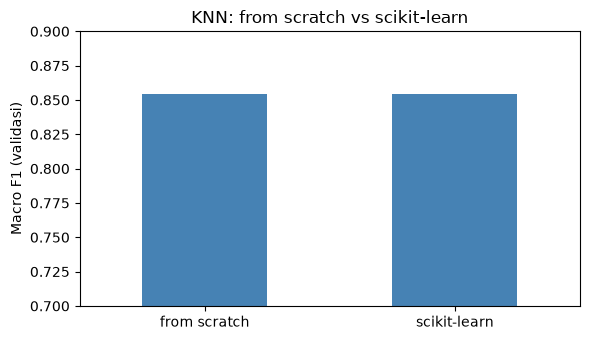

In [40]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score


def inverse_distance_weights(dist):
    # Sama dengan KNN from scratch: bobot 1/jarak^power; jika ada tetangga berjarak 0, hanya tetangga itu yang bersuara.
    w = np.zeros_like(dist)
    zero = dist == 0
    has_zero = zero.any(axis=1)
    w[has_zero] = zero[has_zero]
    w[~has_zero] = 1.0 / dist[~has_zero] ** BEST_POWER
    return w


sk_weights = inverse_distance_weights if BEST_W == 'distance' else 'uniform'
sk_knn = KNeighborsClassifier(n_neighbors=BEST_K, p=BEST_P, weights=sk_weights, algorithm='brute')
sk_knn.fit(X_train, y_train)
sk_val_pred = sk_knn.predict(X_val)

comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, knn_val_pred), accuracy(y_val, knn_val_pred)],
    'scikit-learn': [f1_score(y_val, sk_val_pred, average='macro'), np.mean(sk_val_pred == y_val)],
}, index=['macro F1', 'accuracy'])
print(comparison.round(4))
print(f'Prediksi identik: {np.mean(knn_val_pred == sk_val_pred):.2%}')

fig, ax = plt.subplots(figsize=(6, 3.5))
comparison.loc['macro F1'].plot.bar(ax=ax, color=CFG.PLOT_COLOR)
ax.set_ylim(0.7, 0.9)
ax.set_ylabel('Macro F1 (validasi)')
ax.set_title('KNN: from scratch vs scikit-learn')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

Dengan *hyperparameter* dan data yang sama, prediksi KNN *from scratch* identik (100%) dengan `KNeighborsClassifier(algorithm='brute')` yang diberi fungsi bobot `1/jarak^2` yang sama. Ini menunjukkan perhitungan jarak, pemilihan tetangga, dan voting berbobot sudah benar. Perbedaan utamanya ada pada kecepatan: scikit-learn memakai implementasi C yang lebih cepat.

### Perbandingan SVM

`SVC` menggunakan data, preprocessing, dan parameter kernel yang sama. Pada hasil validasi ini, prediksi linear dan polynomial identik dengan implementasi sendiri. Prediksi Gaussian berbeda pada satu booking.


            macro_f1_scratch  macro_f1_sklearn  accuracy_scratch  accuracy_sklearn  prediction_agreement  scratch_converged  sklearn_converged  sklearn_fit_seconds
kernel                                                                                                                                                             
linear                0.7597            0.7599            0.7976            0.7978                0.9998               True               True              56.7950
polynomial            0.7771            0.7771            0.8137            0.8137                1.0000               True               True              15.0404
gaussian              0.7933            0.7931            0.8267            0.8265                0.9998               True               True              15.4126


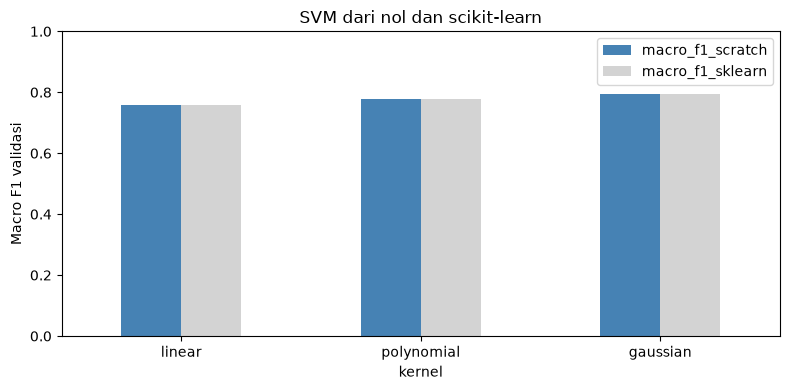

In [41]:
from sklearn.svm import SVC

sk_svm_models = {}
svm_comparison_rows = []
sklearn_kernels = {'linear': 'linear', 'polynomial': 'poly', 'gaussian': 'rbf'}
for kernel, scratch_model in svm_models.items():
    sk_model = SVC(C=scratch_model.C, kernel=sklearn_kernels[kernel],
                   degree=scratch_model.degree, gamma=scratch_model.gamma_,
                   coef0=scratch_model.coef0, tol=scratch_model.tol)
    start = time.time()
    sk_model.fit(X_svm_train, y_train)
    fit_seconds = time.time() - start
    sk_pred = sk_model.predict(X_svm_val)
    sk_svm_models[kernel] = sk_model
    svm_comparison_rows.append({
        'kernel': kernel,
        'macro_f1_scratch': macro_f1(y_val, svm_val_predictions[kernel]),
        'macro_f1_sklearn': f1_score(y_val, sk_pred, average='macro'),
        'accuracy_scratch': accuracy(y_val, svm_val_predictions[kernel]),
        'accuracy_sklearn': accuracy(y_val, sk_pred),
        'prediction_agreement': np.mean(svm_val_predictions[kernel] == sk_pred),
        'scratch_converged': bool(scratch_model.converged_),
        'sklearn_converged': sk_model.fit_status_ == 0,
        'sklearn_fit_seconds': fit_seconds,
    })

svm_comparison = pd.DataFrame(svm_comparison_rows).set_index('kernel')
print(svm_comparison.round(4).to_string())
ax = svm_comparison[['macro_f1_scratch', 'macro_f1_sklearn']].plot.bar(
    figsize=(8, 4), color=[CFG.PLOT_COLOR, 'lightgray'])
ax.set_ylabel('Macro F1 validasi')
ax.set_title('SVM dari nol dan scikit-learn')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


### Perbandingan Naive Bayes dan analisis kesalahan

CategoricalNB memakai matriks diskret, alpha, prior empiris, dan jumlah
kategori yang sama dengan model from scratch. min_categories menyertakan
kategori missing/unseen walaupun tidak muncul dalam training.
Pemeriksaan membandingkan probabilitas dan prediksi, dilanjutkan Macro F1,
akurasi, F1 per kelas, serta confusion matrix.

          from scratch  scikit-learn
macro F1      0.746328      0.746328
accuracy      0.782100      0.782100
Prediksi identik: 100.00%
Selisih probabilitas maksimum: 4.3298697960381105e-15
F1 per kelas [tidak batal, batal]: [0.8415881  0.65106756]
        pred 0  pred 1
asli 0    3169     512
asli 1     681    1113


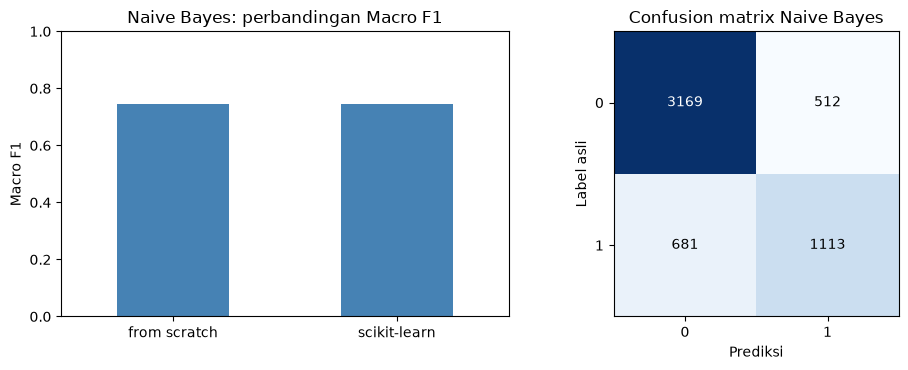

In [42]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import f1_score

sk_nb = CategoricalNB(alpha=NB_BEST_ALPHA,
                      min_categories=nb_preprocessor.n_categories_)
sk_nb.fit(X_nb_train, y_train)
sk_nb_val_pred = sk_nb.predict(X_nb_val)
sk_nb_val_proba = sk_nb.predict_proba(X_nb_val)
assert np.array_equal(nb_model.classes_, sk_nb.classes_)
assert np.allclose(nb_val_proba, sk_nb_val_proba, rtol=1e-10, atol=1e-12)
assert np.array_equal(nb_val_pred, sk_nb_val_pred)

nb_comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, nb_val_pred), accuracy(y_val, nb_val_pred)],
    'scikit-learn': [f1_score(y_val, sk_nb_val_pred, average='macro'),
                     accuracy(y_val, sk_nb_val_pred)],
}, index=['macro F1', 'accuracy'])
print(nb_comparison.round(6).to_string())
print(f'Prediksi identik: {np.mean(nb_val_pred == sk_nb_val_pred):.2%}')
print('Selisih probabilitas maksimum:', np.max(np.abs(nb_val_proba - sk_nb_val_proba)))
print('F1 per kelas [tidak batal, batal]:', f1_per_class(y_val, nb_val_pred))
nb_cm = confusion_matrix(y_val, nb_val_pred)
print(pd.DataFrame(nb_cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
nb_comparison.to_csv(CFG.OUTPUT_DIR / 'naive_bayes_comparison.csv')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
nb_comparison.loc['macro F1'].plot.bar(ax=axes[0], color=CFG.PLOT_COLOR)
axes[0].set(title='Naive Bayes: perbandingan Macro F1', ylim=(0, 1), ylabel='Macro F1')
axes[0].tick_params(axis='x', rotation=0)
axes[1].imshow(nb_cm, cmap='Blues')
for row in range(2):
    for col in range(2):
        axes[1].text(col, row, str(nb_cm[row, col]), ha='center', va='center',
                     color='white' if nb_cm[row, col] > nb_cm.max() / 2 else 'black')
axes[1].set(xticks=[0, 1], yticks=[0, 1], xlabel='Prediksi',
            ylabel='Label asli', title='Confusion matrix Naive Bayes')
fig.tight_layout()
nb_plot_dir = CFG.OUTPUT_DIR / 'visualization' / 'naive_bayes'
nb_plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(nb_plot_dir / 'comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Pembahasan:**

Dengan alpha tetap 1, CV memilih hingga 40 bin. Macro F1 CV adalah 0,7477 (std 0,0043).
Pada 5.475 data validasi, Macro F1 mencapai 0,7463 dan akurasi 0,7821.
Prediksi identik 100% dengan scikit-learn; selisih probabilitas maksimum sekitar
4,33e-15. F1 kelas tidak batal 0,8416, sedangkan kelas batal 0,6511.
Confusion matrix berisi TN=3.169, FP=512, FN=681, TP=1.113. Model lebih sering
melewatkan pembatalan daripada salah menandai pesanan yang tidak batal.

Hasil ini berasal dari split seed 42 yang sama dengan model lain. Skor ini belum
merupakan skor leaderboard Kaggle. Tabel dihitung ulang saat notebook dijalankan.
Kesamaan dengan scikit-learn memeriksa perhitungan model pada preprocessing
yang sama, bukan membuktikan asumsi independensi cocok dengan dataset.
Pada data penginapan, tanggal kedatangan, lama menginap, harga, dan kanal
pemesanan dapat saling berkaitan; Naive Bayes tetap memperlakukan kontribusinya
secara independen bersyarat terhadap kelas. Diskretisasi juga membuang sebagian
rincian nilai numerik. Jumlah bin dipilih lewat CV untuk menyeimbangkan rincian
tersebut dengan kecukupan frekuensi setiap kategori.

### Perbandingan Decision Tree

Pembanding adalah `DecisionTreeClassifier(criterion='entropy', ccp_alpha=...)` untuk C4.5, sesuai spesifikasi. scikit-learn tidak menerima nilai kosong dan kategori teks, sehingga datanya memakai `Preprocessor(scale=False)` (imputasi dan *one-hot*, tanpa *scaling*). Perbedaan input ini dan perbedaan algoritma (CART biner dengan entropi di scikit-learn, C4.5 dengan gain ratio di implementasi sendiri) membuat hasil tidak identik; yang dibandingkan adalah kualitas prediksinya.

             from scratch  scikit-learn
macro F1           0.8333        0.8297
accuracy           0.8574        0.8511
jumlah daun     1221.0000     1059.0000
Kesesuaian prediksi: 89.15%


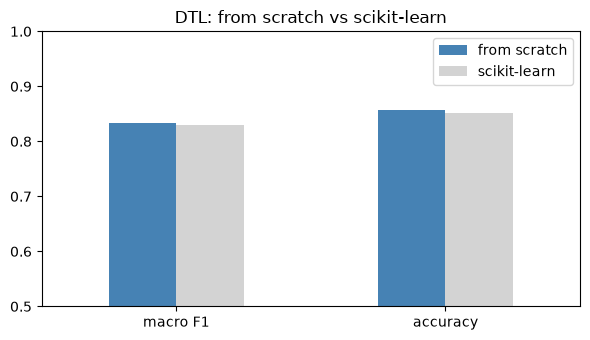

In [43]:
from sklearn.tree import DecisionTreeClassifier

dtl_sk_prep = Preprocessor(scale=False, min_category_freq=20, add_derived=False, feature_weights=None)
X_dtl_sk_train = dtl_sk_prep.fit_transform(train_set)
X_dtl_sk_val = dtl_sk_prep.transform(val_set)
start = time.time()
sk_dtl = DecisionTreeClassifier(criterion='entropy', max_depth=DTL_BEST_DEPTH, min_samples_leaf=DTL_BEST_LEAF,
                                ccp_alpha=DTL_BEST_CCP, random_state=CFG.SEED).fit(X_dtl_sk_train, y_train)
sk_dtl_seconds = time.time() - start
sk_dtl_pred = sk_dtl.predict(X_dtl_sk_val)
dtl_comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, dtl_val_pred), accuracy(y_val, dtl_val_pred), dtl.get_n_leaves()],
    'scikit-learn': [f1_score(y_val, sk_dtl_pred, average='macro'), np.mean(sk_dtl_pred == y_val), sk_dtl.get_n_leaves()],
}, index=['macro F1', 'accuracy', 'jumlah daun'])
print(dtl_comparison.round(4).to_string())
print(f'Kesesuaian prediksi: {np.mean(dtl_val_pred == sk_dtl_pred):.2%}')
ax = dtl_comparison.loc[['macro F1', 'accuracy']].plot.bar(figsize=(6, 3.5), color=[CFG.PLOT_COLOR, 'lightgray'])
ax.set_ylim(0.5, 1)
ax.set_title('DTL: from scratch vs scikit-learn')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [44]:
c45_alpha = DTL_BEST_CCP if DTL_BEST_CCP > 0 else DTL_CCP_GRID[1]
dtl_variant_defs = {
    'ID3 (entropy)': dict(criterion='entropy'),
    'C4.5 (entropy + ccp_alpha)': dict(criterion='entropy', ccp_alpha=c45_alpha),
    'CART (gini)': dict(criterion='gini'),
}
dtl_variant_rows = [{'model': 'C4.5 from scratch', 'val_macro_f1': macro_f1(y_val, dtl_val_pred),
                     'val_accuracy': accuracy(y_val, dtl_val_pred), 'jumlah_daun': dtl.get_n_leaves()}]
for variant_name, variant_params in dtl_variant_defs.items():
    sk_variant = DecisionTreeClassifier(max_depth=DTL_BEST_DEPTH, min_samples_leaf=DTL_BEST_LEAF,
                                        random_state=CFG.SEED, **variant_params).fit(X_dtl_sk_train, y_train)
    variant_pred = sk_variant.predict(X_dtl_sk_val)
    dtl_variant_rows.append({'model': f'scikit-learn {variant_name}',
                             'val_macro_f1': f1_score(y_val, variant_pred, average='macro'),
                             'val_accuracy': float(np.mean(variant_pred == y_val)),
                             'jumlah_daun': sk_variant.get_n_leaves()})
dtl_variant_table = pd.DataFrame(dtl_variant_rows)
print(f'ccp_alpha untuk varian C4.5 scikit-learn: {c45_alpha:g}')
print(dtl_variant_table.round(4).to_string(index=False))
dtl_variant_table.to_csv(CFG.OUTPUT_DIR / 'dtl_sklearn_variants.csv', index=False)

ccp_alpha untuk varian C4.5 scikit-learn: 0.0002
                                  model  val_macro_f1  val_accuracy  jumlah_daun
                      C4.5 from scratch        0.8333        0.8574         1221
             scikit-learn ID3 (entropy)        0.8297        0.8511         1059
scikit-learn C4.5 (entropy + ccp_alpha)        0.8376        0.8595          491
               scikit-learn CART (gini)        0.8292        0.8504         1241


### Perbandingan Logistic Regression

Hyperparameter dan data sama dengan model sendiri. $C = 1/(\alpha n)$ menyamakan skala penalti. Scikit-learn memakai solver `saga`, satu-satunya yang mendukung L1 dan Elastic Net.

            macro_f1_scratch  macro_f1_sklearn  prediction_agreement  max_abs_coef_diff  zero_coef_scratch  zero_coef_sklearn  sklearn_fit_seconds
penalty                                                                                                                                           
l1                    0.7628            0.7633                0.9918             1.7072                  3                  7             150.5453
l2                    0.7633            0.7635                0.9921             1.1897                  1                  1              51.4805
elasticnet            0.7630            0.7632                0.9920             1.3504                  3                  6              80.5255


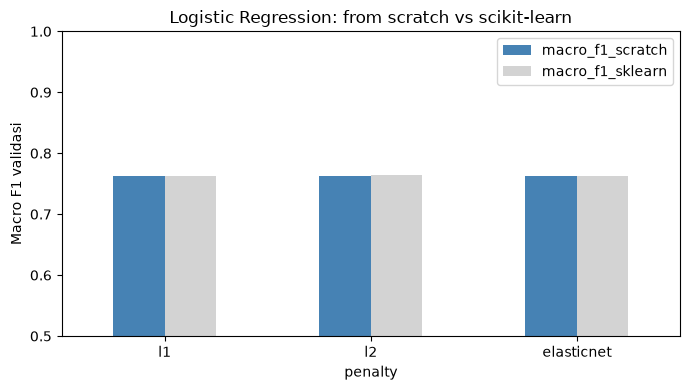

In [45]:
import sklearn
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

SK_NEW_API = tuple(int(v) for v in sklearn.__version__.split('.')[:2]) >= (1, 8)


def make_sklearn_logreg(penalty, C, l1_ratio=0.5):
    common = dict(C=C, solver='saga', max_iter=5000, tol=1e-6)
    if SK_NEW_API:
        return SkLogisticRegression(l1_ratio={'l2': 0.0, 'l1': 1.0, 'elasticnet': l1_ratio}[penalty], **common)
    if penalty == 'elasticnet':
        return SkLogisticRegression(penalty='elasticnet', l1_ratio=l1_ratio, **common)
    return SkLogisticRegression(penalty=penalty, **common)


lr_cmp_rows = []
sk_lr_models = {}
for penalty, model in lr_models.items():
    C = 1.0 / (model.alpha * len(y_train))
    start = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sk_model = make_sklearn_logreg(penalty, C, LR_PARAMS['l1_ratio']).fit(X_lr_train, y_train)
    sk_pred = sk_model.predict(X_lr_val)
    sk_lr_models[penalty] = sk_model
    lr_cmp_rows.append({
        'penalty': penalty,
        'macro_f1_scratch': macro_f1(y_val, lr_val_predictions[penalty]),
        'macro_f1_sklearn': f1_score(y_val, sk_pred, average='macro'),
        'prediction_agreement': np.mean(lr_val_predictions[penalty] == sk_pred),
        'max_abs_coef_diff': np.abs(model.coef_ - sk_model.coef_[0]).max(),
        'zero_coef_scratch': int((model.coef_ == 0).sum()),
        'zero_coef_sklearn': int((sk_model.coef_[0] == 0).sum()),
        'sklearn_fit_seconds': time.time() - start,
    })
lr_comparison = pd.DataFrame(lr_cmp_rows).set_index('penalty')
print(lr_comparison.round(4).to_string())
ax = lr_comparison[['macro_f1_scratch', 'macro_f1_sklearn']].plot.bar(figsize=(7, 4), color=[CFG.PLOT_COLOR, 'lightgray'])
ax.set_ylim(0.5, 1)
ax.set_ylabel('Macro F1 validasi')
ax.set_title('Logistic Regression: from scratch vs scikit-learn')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [46]:
knn_path = CFG.MODEL_DIR / 'knn.pkl'
prep_path = CFG.MODEL_DIR / 'preprocessor.pkl'
knn.save(knn_path)
preprocessor.save(prep_path)

loaded_knn = KNN.load(knn_path)
loaded_prep = Preprocessor.load(prep_path)
reloaded_pred = loaded_knn.predict(loaded_prep.transform(val_set))
print('Prediksi model hasil load sama dengan model asli:', np.array_equal(reloaded_pred, knn_val_pred))

Prediksi model hasil load sama dengan model asli: True


### Menyimpan dan memuat SVM

Model setiap kernel dan preprocessor SVM disimpan di `output/models/`. Setelah dimuat kembali, ketiganya menghasilkan prediksi validasi yang sama dengan sebelum disimpan.


In [47]:
svm_prep_path = CFG.MODEL_DIR / 'svm_preprocessor.pkl'
svm_preprocessor.save(svm_prep_path)
loaded_svm_preprocessor = Preprocessor.load(svm_prep_path)
X_svm_val_loaded = loaded_svm_preprocessor.transform(val_set)

for kernel, model in svm_models.items():
    model_path = CFG.MODEL_DIR / f'svm_{kernel}.pkl'
    model.save(model_path)
    loaded_svm = SVM.load(model_path)
    loaded_pred = loaded_svm.predict(X_svm_val_loaded)
    assert np.array_equal(loaded_pred, svm_val_predictions[kernel])
    print(f'SVM {kernel}: prediksi sesudah save/load sama')


SVM linear: prediksi sesudah save/load sama
SVM polynomial: prediksi sesudah save/load sama
SVM gaussian: prediksi sesudah save/load sama


### Menyimpan dan memuat Naive Bayes

Model dan preprocessor disimpan bersama sebagai dua berkas. Median, batas
interval, dan pemetaan kategori hasil training digunakan kembali saat prediksi.

In [48]:
nb_model.save(CFG.MODEL_DIR / 'naive_bayes.pkl')
nb_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_preprocessor.pkl')
loaded_nb = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes.pkl')
loaded_nb_prep = NaiveBayesPreprocessor.load(CFG.MODEL_DIR / 'naive_bayes_preprocessor.pkl')
nb_reloaded_X = loaded_nb_prep.transform(val_set)
assert np.array_equal(loaded_nb.predict(nb_reloaded_X), nb_val_pred)
assert np.array_equal(loaded_nb.predict_proba(nb_reloaded_X), nb_val_proba)
print('Naive Bayes: prediksi dan probabilitas sebelum/sesudah save-load identik')

Naive Bayes: prediksi dan probabilitas sebelum/sesudah save-load identik


### Menyimpan dan memuat Decision Tree dan Logistic Regression

Setelah dimuat kembali, prediksi validasi harus sama dengan sebelum disimpan.

In [49]:
dtl.save(CFG.MODEL_DIR / 'dtl.pkl')
loaded_dtl = DecisionTree.load(CFG.MODEL_DIR / 'dtl.pkl')
assert np.array_equal(loaded_dtl.predict(val_set[RAW_FEATURES]), dtl_val_pred)
assert np.array_equal(loaded_dtl.predict_proba(val_set[RAW_FEATURES]), dtl.predict_proba(val_set[RAW_FEATURES]))
print('DTL: prediksi sebelum/sesudah save-load identik')

lr_preprocessor.save(CFG.MODEL_DIR / 'logreg_preprocessor.pkl')
loaded_lr_prep = Preprocessor.load(CFG.MODEL_DIR / 'logreg_preprocessor.pkl')
X_lr_val_loaded = loaded_lr_prep.transform(val_set)
for penalty, model in lr_models.items():
    model.save(CFG.MODEL_DIR / f'logreg_{penalty}.pkl')
    loaded = LogisticRegression.load(CFG.MODEL_DIR / f'logreg_{penalty}.pkl')
    assert np.array_equal(loaded.predict(X_lr_val_loaded), lr_val_predictions[penalty])
    assert np.array_equal(loaded.coef_, model.coef_)
    print(f'Logistic Regression {penalty}: prediksi sesudah save-load sama')

DTL: prediksi sebelum/sesudah save-load identik
Logistic Regression l1: prediksi sesudah save-load sama
Logistic Regression l2: prediksi sesudah save-load sama
Logistic Regression elasticnet: prediksi sesudah save-load sama


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [50]:
# Model akhir: preprocessor dan KNN di-fit ulang pada seluruh train.csv (tanpa duplikat) dengan bobot akhir.
full_train = drop_duplicate_rows(train_df)
final_prep = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=FINAL_FW).fit(full_train)
final_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(final_prep.transform(full_train),
                                                                          full_train[TARGET].to_numpy())

test_pred = final_knn.predict(final_prep.transform(test_df))   # Test hanya ditransformasi.
submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': test_pred.astype(int)})

assert len(submission) == len(test_df) and submission['id'].is_unique
assert set(submission['is_canceled'].unique()) <= {0, 1}
submission_path = CFG.OUTPUT_DIR / 'submission_knn.csv'
submission.to_csv(submission_path, index=False)
final_knn.save(CFG.MODEL_DIR / 'knn_final.pkl')
final_prep.save(CFG.MODEL_DIR / 'preprocessor_final.pkl')

print(submission_path, submission.shape)
print('Proporsi prediksi batal di test: %.3f' % submission['is_canceled'].mean())
submission.head()

c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_knn.csv (6844, 2)
Proporsi prediksi batal di test: 0.299


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submisi pembanding KNN (konfigurasi sebelumnya)

Konfigurasi KNN sebelum optimasi (`CFG.FEATURE_WEIGHTS`, k = 21, voting `1/jarak`) pernah dikirim ke Kaggle. Sel berikut membuat ulang submisi tersebut ke `submission_knn_v1.csv`, sehingga submisi lama tetap dapat direproduksi dan dibandingkan dengan submisi akhir.

In [51]:
v1_prep = Preprocessor(feature_weights=CFG.FEATURE_WEIGHTS).fit(full_train)
v1_knn = KNN(**CFG.KNN_V1_PARAMS).fit(v1_prep.transform(full_train), full_train[TARGET].to_numpy())
v1_test_pred = v1_knn.predict(v1_prep.transform(test_df))
v1_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': v1_test_pred.astype(int)})
v1_submission.to_csv(CFG.OUTPUT_DIR / 'submission_knn_v1.csv', index=False)
print(CFG.OUTPUT_DIR / 'submission_knn_v1.csv', v1_submission.shape)
print(f'Prediksi sama dengan submisi akhir: {np.mean(v1_test_pred == test_pred):.2%}')

c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_knn_v1.csv (6844, 2)
Prediksi sama dengan submisi akhir: 96.61%


### Submission SVM

Gaussian dipilih karena Macro F1 validasinya paling tinggi, yaitu 0,7933. Model dan preprocessor dilatih ulang pada seluruh train setelah penghapusan duplikat. Test diproses dengan preprocessor tersebut, lalu prediksinya disimpan ke `submission_svm.csv`.


In [52]:
svm_final_preprocessor = Preprocessor(scale=True, min_category_freq=20,
                                      add_derived=True, feature_weights=None)
X_svm_full = svm_final_preprocessor.fit_transform(full_train)
X_svm_test = svm_final_preprocessor.transform(test_df)
svm_final = SVM(C=CFG.SVM_C, kernel=BEST_SVM_KERNEL, degree=CFG.SVM_DEGREE,
                tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_final.fit(X_svm_full, full_train[TARGET].to_numpy())
if not svm_final.converged_:
    raise RuntimeError('SVM final belum konvergen. Naikkan CFG.SVM_MAX_ITER sebelum membuat submission.')

svm_test_pred = svm_final.predict(X_svm_test)
svm_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': svm_test_pred.astype(int)})
sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert svm_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_submission['id'].equals(sample_submission['id'])
assert len(svm_submission) == len(test_df) and svm_submission['id'].is_unique
assert set(svm_submission['is_canceled'].unique()) <= {0, 1}

svm_submission_path = CFG.OUTPUT_DIR / 'submission_svm.csv'
svm_submission.to_csv(svm_submission_path, index=False)
svm_final.save(CFG.MODEL_DIR / 'svm_final.pkl')
svm_final_preprocessor.save(CFG.MODEL_DIR / 'svm_preprocessor_final.pkl')
print(svm_submission_path, svm_submission.shape)
print('Proporsi prediksi batal di test: %.3f' % svm_submission['is_canceled'].mean())
svm_submission.head()


c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_svm.csv (6844, 2)
Proporsi prediksi batal di test: 0.269


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submission Naive Bayes

Parameter CV dipertahankan. Preprocessor dan model dilatih ulang pada seluruh
train setelah penghapusan duplikat; test hanya ditransformasi. ID dibaca sebagai
teks dan urutannya diperiksa terhadap sample submission.

In [53]:
nb_full_train = drop_duplicate_rows(train_df)
nb_final_preprocessor = NaiveBayesPreprocessor(n_bins=NB_BEST_BINS).fit(nb_full_train)
nb_final_model = NaiveBayes(alpha=NB_BEST_ALPHA,
                            min_categories=nb_final_preprocessor.n_categories_)
nb_final_model.fit(nb_final_preprocessor.transform(nb_full_train),
                   nb_full_train[TARGET].to_numpy())
X_nb_test = nb_final_preprocessor.transform(test_df)
nb_test_pred = nb_final_model.predict(X_nb_test)
nb_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': nb_test_pred.astype(int)})
nb_sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert nb_submission.columns.tolist() == nb_sample_submission.columns.tolist()
assert nb_submission['id'].equals(nb_sample_submission['id'])
assert len(nb_submission) == len(test_df) and nb_submission['id'].is_unique
assert set(nb_submission['is_canceled'].unique()) <= {0, 1}
nb_submission_path = CFG.OUTPUT_DIR / 'submission_naive_bayes.csv'
nb_submission.to_csv(nb_submission_path, index=False)
nb_final_model.save(CFG.MODEL_DIR / 'naive_bayes_final.pkl')
nb_final_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_preprocessor_final.pkl')
nb_final_loaded = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes_final.pkl')
nb_final_prep_loaded = NaiveBayesPreprocessor.load(
    CFG.MODEL_DIR / 'naive_bayes_preprocessor_final.pkl')
assert np.array_equal(
    nb_final_loaded.predict(nb_final_prep_loaded.transform(test_df)), nb_test_pred)
print(nb_submission_path, nb_submission.shape)
print('Proporsi prediksi batal:', nb_submission['is_canceled'].mean())
nb_submission.head()

c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_naive_bayes.csv (6844, 2)
Proporsi prediksi batal: 0.2822910578609001


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1
3,25408a48,0
4,621586b6,0


### Submission Decision Tree dan Logistic Regression

Model dilatih ulang pada seluruh `train.csv` tanpa duplikat. Test hanya ditransformasi. Format dan urutan `id` diperiksa terhadap `sample_submission.csv`.

In [54]:
final_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})


def write_submission(pred, name):
    sub = pd.DataFrame({'id': test_df['id'], 'is_canceled': np.asarray(pred).astype(int)})
    assert sub.columns.tolist() == final_sample.columns.tolist()
    assert sub['id'].equals(final_sample['id'])
    assert len(sub) == len(test_df) and sub['id'].is_unique
    assert set(sub['is_canceled'].unique()) <= {0, 1}
    path = CFG.OUTPUT_DIR / name
    sub.to_csv(path, index=False)
    print(path, sub.shape, 'proporsi batal: %.3f' % sub['is_canceled'].mean())
    return sub


y_full = full_train[TARGET].to_numpy()

dtl_final = DecisionTree(**DTL_BEST_PARAMS).fit(full_train[RAW_FEATURES], y_full)
dtl_test_pred = dtl_final.predict(test_df[RAW_FEATURES])
dtl_submission = write_submission(dtl_test_pred, 'submission_dtl.csv')
dtl_final.save(CFG.MODEL_DIR / 'dtl_final.pkl')

lr_final_preprocessor = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=None)
X_lr_full = lr_final_preprocessor.fit_transform(full_train)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    lr_final = LogisticRegression(penalty=LR_BEST_PENALTY, alpha=LR_BEST_ALPHA, **LR_PARAMS).fit(X_lr_full, y_full)
lr_test_pred = lr_final.predict(lr_final_preprocessor.transform(test_df))
lr_submission = write_submission(lr_test_pred, 'submission_logreg.csv')
lr_final.save(CFG.MODEL_DIR / 'logreg_final.pkl')
lr_final_preprocessor.save(CFG.MODEL_DIR / 'logreg_preprocessor_final.pkl')

c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_dtl.csv (6844, 2) proporsi batal: 0.283
c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_logreg.csv (6844, 2) proporsi batal: 0.270


### Verifikasi Submission Akhir Kaggle

Submission Kaggle yang dikumpulkan adalah `output/submission_knn.csv` (KNN *from scratch* tanpa *ensemble*). Sel di bawah memeriksa bahwa model tersimpan yang dimuat kembali dan pelatihan ulang dari awal menghasilkan prediksi yang identik dengan berkas tersebut, sehingga notebook reproducible. Isi skor leaderboard Kaggle pada README setelah submisi diunggah.

In [55]:
import hashlib

FINAL_SUBMISSION_PATH = CFG.OUTPUT_DIR / 'submission_knn.csv'
loaded_final_prep = Preprocessor.load(CFG.MODEL_DIR / 'preprocessor_final.pkl')
loaded_final_knn = KNN.load(CFG.MODEL_DIR / 'knn_final.pkl')
assert np.array_equal(loaded_final_knn.predict(loaded_final_prep.transform(test_df)), test_pred)

rerun_prep = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=FINAL_FW).fit(full_train)
rerun_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(
    rerun_prep.transform(full_train), full_train[TARGET].to_numpy())
rerun_pred = rerun_knn.predict(rerun_prep.transform(test_df))
assert np.array_equal(rerun_pred, test_pred)

saved_final = pd.read_csv(FINAL_SUBMISSION_PATH, dtype={'id': str})
assert saved_final['id'].equals(test_df['id'])
assert np.array_equal(saved_final['is_canceled'].to_numpy(), rerun_pred)
print('SHA-256', FINAL_SUBMISSION_PATH.name, hashlib.sha256(FINAL_SUBMISSION_PATH.read_bytes()).hexdigest())
print('Model tersimpan dan pelatihan ulang menghasilkan prediksi identik dengan submission.')

SHA-256 submission_knn.csv 92d0395e3a84c828f894846698179fb40627886a9f17abf58fdf56d4411d5ca3
Model tersimpan dan pelatihan ulang menghasilkan prediksi identik dengan submission.


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [56]:
cm = confusion_matrix(y_val, knn_val_pred)
print('Confusion matrix (baris = asli, kolom = prediksi):')
print(pd.DataFrame(cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
print('F1 per kelas:', f1_per_class(y_val, knn_val_pred).round(4))

err = val_set.assign(pred=knn_val_pred, wrong=knn_val_pred != y_val)
lead_bins = pd.cut(err['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print('\nTingkat kesalahan per lead time:')
print(err.groupby(lead_bins, observed=True)['wrong'].agg(['mean', 'size']).round(3))
print('\nTingkat kesalahan per kanal:')
print(err.groupby('booking_channel')['wrong'].agg(['mean', 'size']).round(3))

Confusion matrix (baris = asli, kolom = prediksi):
        pred 0  pred 1
asli 0    3383     298
asli 1     396    1398
F1 per kelas: [0.907  0.8011]

Tingkat kesalahan per lead time:
                      mean  size
days_before_arrival             
(-1, 7]              0.065   802
(7, 30]              0.107   965
(30, 90]             0.154  1562
(90, 180]            0.179  1133
(180, 500]           0.059   767

Tingkat kesalahan per kanal:
                      mean  size
booking_channel                 
Airline              0.188    16
Complimentary        0.017    58
Corporate            0.068   309
Offline Agent        0.068  1573
Online Travel Agent  0.160  3519


**Insights:**

- F1 kelas tidak batal (0,907) jauh lebih tinggi daripada kelas batal (0,801). Kelas batal tetap menjadi titik lemah yang menurunkan Macro F1, walaupun F1-nya naik dari sekitar 0,79 pada konfigurasi sebelumnya.
- Kesalahan paling banyak terjadi pada pesanan dengan lead time menengah (30–180 hari, tingkat salah 15–18%), di mana pola batal dan tidak batal paling bercampur. Lead time di bawah 7 hari atau di atas 180 hari jauh lebih mudah ditebak (sekitar 6%).
- Di antara kanal yang besar, *Online Travel Agent* memiliki tingkat salah tertinggi (16%) dibanding *Offline Agent* atau *Corporate* (sekitar 7%). Kanal *Airline* hanya berisi 16 pesanan, sehingga tingkat salahnya tidak stabil.
- Perbaikan berikutnya: bandingkan dengan DTL, yang menangani interaksi fitur secara eksplisit.

### Analisis kesalahan SVM

Confusion matrix menunjukkan jumlah prediksi benar dan salah. Baris menunjukkan label asli dan kolom menunjukkan prediksi. F1 per kelas digunakan untuk menilai hasil pada booking batal dan tidak batal.


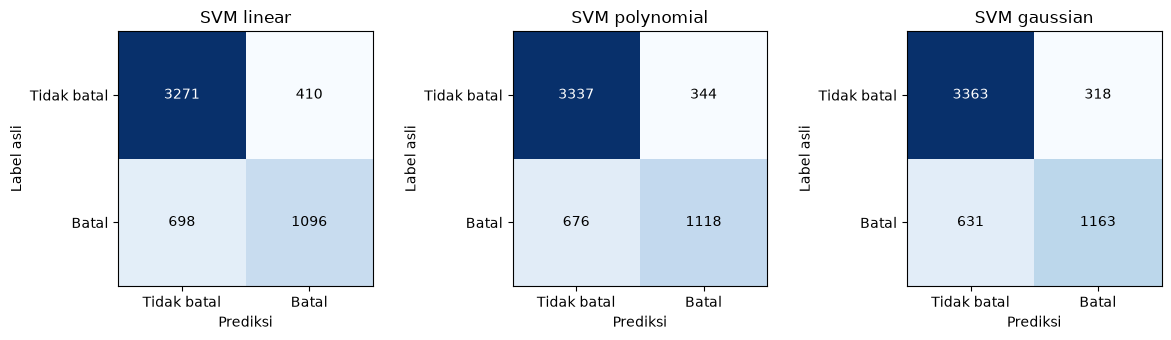

,kernel,f1_tidak_batal,f1_batal
0,linear,0.855163,0.664242
1,polynomial,0.867429,0.686732
2,gaussian,0.876352,0.710229


In [57]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
svm_class_rows = []
for ax, (kernel, pred) in zip(axes, svm_val_predictions.items()):
    svm_cm = confusion_matrix(y_val, pred)
    ax.imshow(svm_cm, cmap='Blues')
    for row in range(2):
        for column in range(2):
            color = 'white' if svm_cm[row, column] > svm_cm.max() / 2 else 'black'
            ax.text(column, row, str(svm_cm[row, column]), ha='center', va='center', color=color)
    ax.set_xticks([0, 1], ['Tidak batal', 'Batal'])
    ax.set_yticks([0, 1], ['Tidak batal', 'Batal'])
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label asli')
    ax.set_title(f'SVM {kernel}')
    class_f1 = f1_per_class(y_val, pred)
    svm_class_rows.append({'kernel': kernel, 'f1_tidak_batal': class_f1[0], 'f1_batal': class_f1[1]})
plt.tight_layout()
plt.show()
pd.DataFrame(svm_class_rows)


---

# Cost-Sensitive Classification (Bonus) <a name="12"></a>

---

Tidak semua kesalahan prediksi sama mahalnya. Dengan kelas positif = batal (`is_canceled = 1`):

- **False Positive (FP)**: pesanan diprediksi batal padahal tamu datang. Kalau kamarnya sudah dijual lagi, penginapan menjadi *overbooked*.
- **False Negative (FN)**: pesanan diprediksi datang padahal batal. Akibatnya ada kamar kosong yang tidak terjual.

Sesuai spesifikasi, biaya FP dianggap **2 kali** biaya FN. Prediksi yang benar tidak menimbulkan biaya.

Model yang dipakai tetap KNN terbaik dari bagian Modeling. Yang berubah adalah **aturan keputusannya**. KNN memprediksi kelas dengan probabilitas terbesar, sehingga pesanan diprediksi batal jika $P(\text{batal}) > 0{,}5$. Aturan ini hanya optimal jika biaya FP dan FN sama.

Menurut aturan keputusan Bayes dengan biaya (Elkan, 2001), pesanan sebaiknya diprediksi batal hanya jika biaya harapannya lebih kecil daripada memprediksi datang:

$$(1 - p) \cdot C_{FP} < p \cdot C_{FN} \iff p > \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{2}{3}$$

dengan $p = P(\text{batal})$. Jadi model harus lebih yakin sebelum memprediksi batal.

Pada KNN, menaikkan ambang ke 2/3 sama dengan memberi bobot 2 pada suara tetangga kelas tidak batal saat voting.

Probabilitas KNN tidak terkalibrasi sempurna, jadi ambang 2/3 belum tentu yang terbaik untuk data ini. Karena itu ambang juga dicari langsung dengan meminimalkan biaya pada probabilitas *out-of-fold* data latih. Data validasi hanya dipakai untuk mengevaluasi.

In [58]:
# Matriks biaya: baris = label asli, kolom = prediksi.
COST_FP = 2.0   # Diprediksi batal padahal tamu datang, kamar bisa overbooked.
COST_FN = 1.0   # Diprediksi datang padahal batal, kamar kosong tidak terjual.
print(pd.DataFrame([[0, COST_FP], [COST_FN, 0]], index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))

# Ambang dari aturan keputusan Bayes dengan biaya (Elkan, 2001).
BAYES_THRESHOLD = COST_FP / (COST_FP + COST_FN)
print(f'\nAmbang teoretis: P(batal) > {BAYES_THRESHOLD:.3f}')

default_cost = misclassification_cost(y_val, knn_val_pred, COST_FP, COST_FN)
print(f'Biaya model default (ambang 0,5) di validasi: {default_cost:.0f}  ({default_cost / len(y_val):.4f} per pesanan)')

        pred 0  pred 1
asli 0     0.0     2.0
asli 1     1.0     0.0

Ambang teoretis: P(batal) > 0.667
Biaya model default (ambang 0,5) di validasi: 992  (0.1812 per pesanan)


Ambang dengan biaya CV minimum   : 0.71
Ambang dengan Macro F1 CV maksimum: 0.50


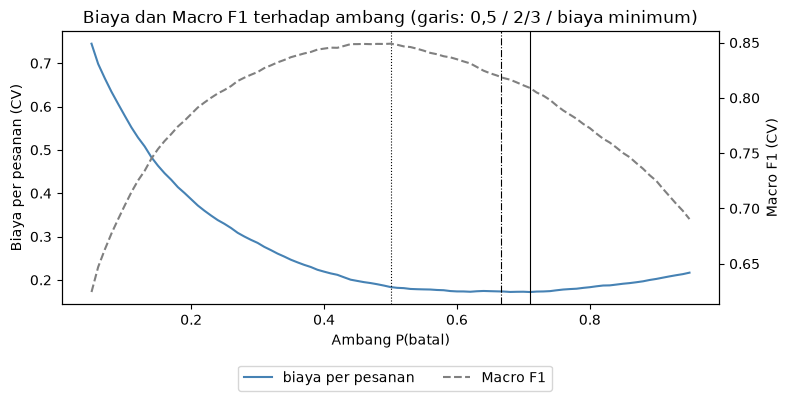

In [59]:
# Probabilitas out-of-fold pada data latih, supaya ambang tidak dipilih dari data validasi.
# Preprocessor di-fit ulang di setiap fold, sama seperti saat tuning hyperparameter.
oof_proba = np.zeros(len(train_set))
for tr_idx, va_idx in stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    pp = Preprocessor(feature_weights=FINAL_FW).fit(fold_tr)
    fold_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(pp.transform(fold_tr), y_train[tr_idx])
    oof_proba[va_idx] = fold_knn.predict_proba(pp.transform(fold_va))[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep_rows = []
for t in thresholds:
    pred = (oof_proba > t).astype(int)
    sweep_rows.append({
        'threshold': t,
        'cost_per_booking': misclassification_cost(y_train, pred, COST_FP, COST_FN) / len(y_train),
        'macro_f1': macro_f1(y_train, pred),
    })
sweep = pd.DataFrame(sweep_rows)

CV_THRESHOLD = float(sweep.loc[sweep['cost_per_booking'].idxmin(), 'threshold'])
F1_THRESHOLD = float(sweep.loc[sweep['macro_f1'].idxmax(), 'threshold'])
print(f'Ambang dengan biaya CV minimum   : {CV_THRESHOLD:.2f}')
print(f'Ambang dengan Macro F1 CV maksimum: {F1_THRESHOLD:.2f}')

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sweep['threshold'], sweep['cost_per_booking'], color=CFG.PLOT_COLOR, label='biaya per pesanan')
ax1.set_xlabel('Ambang P(batal)')
ax1.set_ylabel('Biaya per pesanan (CV)')
ax2 = ax1.twinx()
ax2.plot(sweep['threshold'], sweep['macro_f1'], color='gray', linestyle='--', label='Macro F1')
ax2.set_ylabel('Macro F1 (CV)')
for t, style in [(0.5, ':'), (BAYES_THRESHOLD, '-.'), (CV_THRESHOLD, '-')]:
    ax1.axvline(t, color='black', linestyle=style, linewidth=0.8)
ax1.set_title('Biaya dan Macro F1 terhadap ambang (garis: 0,5 / 2/3 / biaya minimum)')
fig.legend(loc='lower center', ncol=2)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

                  ambang    TN   FP   FN    TP  total_biaya  biaya_per_pesanan  precision_batal  recall_batal  macro_f1
aturan                                                                                                                 
default            0.500  3383  298  396  1398        992.0             0.1812           0.8243        0.7793    0.8541
Bayes 2/3          0.667  3542  139  630  1164        908.0             0.1658           0.8933        0.6488    0.8269
biaya minimum CV   0.710  3570  111  700  1094        922.0             0.1684           0.9079        0.6098    0.8138

Penurunan biaya dibanding ambang default: 7.1%


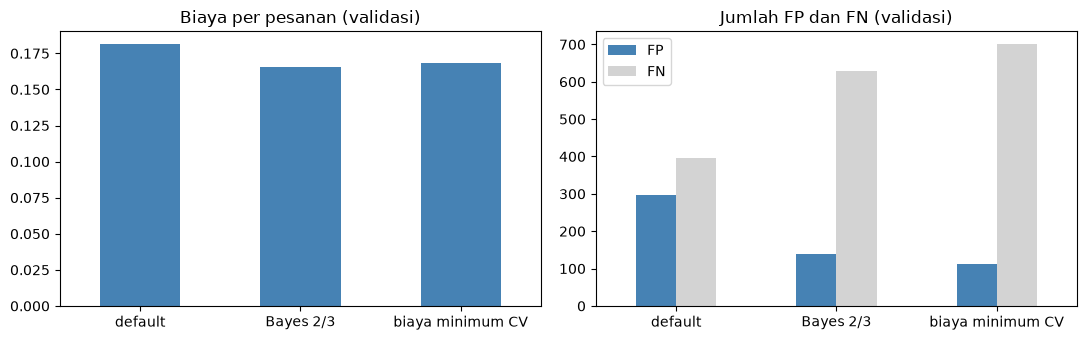

In [60]:
# Evaluasi ketiga ambang di data validasi dengan model KNN yang sama.
val_proba = knn.predict_proba(X_val)[:, 1]
# Ambang 0,5 harus memberi prediksi yang sama dengan knn.predict.
assert np.array_equal((val_proba > 0.5).astype(int), knn_val_pred)

cost_rows = []
for name, t in [('default', 0.5), ('Bayes 2/3', BAYES_THRESHOLD), ('biaya minimum CV', CV_THRESHOLD)]:
    pred = (val_proba > t).astype(int)
    (tn, fp), (fn, tp) = confusion_matrix(y_val, pred)
    total = misclassification_cost(y_val, pred, COST_FP, COST_FN)
    cost_rows.append({
        'aturan': name, 'ambang': round(t, 3), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'total_biaya': total,
        'biaya_per_pesanan': total / len(y_val),
        'precision_batal': tp / (tp + fp) if tp + fp > 0 else 0.0,
        'recall_batal': tp / (tp + fn) if tp + fn > 0 else 0.0,
        'macro_f1': macro_f1(y_val, pred),
    })
cost_table = pd.DataFrame(cost_rows).set_index('aturan')
print(cost_table.round(4).to_string())

saving = 1 - cost_table.loc['biaya minimum CV', 'total_biaya'] / cost_table.loc['default', 'total_biaya']
print(f'\nPenurunan biaya dibanding ambang default: {saving:.1%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cost_table['biaya_per_pesanan'].plot.bar(ax=axes[0], color=CFG.PLOT_COLOR)
axes[0].set_title('Biaya per pesanan (validasi)')
cost_table[['FP', 'FN']].plot.bar(ax=axes[1], color=[CFG.PLOT_COLOR, 'lightgray'])
axes[1].set_title('Jumlah FP dan FN (validasi)')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

- **Biaya turun 7,1–8,5%.** Dengan ambang default 0,5, total biaya di validasi adalah 992 (0,181 per pesanan). Ambang biaya minimum hasil CV (0,71) menurunkannya menjadi 922 (0,168 per pesanan), dan ambang teoretis 2/3 menjadi 908 (0,166 per pesanan).
- **FP turun lebih dari setengah.** Dengan ambang CV, FP turun dari 298 menjadi 111, sedangkan FN naik dari 396 menjadi 700. Pengurangan 187 FP menghemat 374, sementara tambahan 304 FN hanya menambah 304, sehingga biaya bersih turun 70.
- **Ambang hasil CV (0,71) sedikit di atas ambang teoretis 2/3 (0,667), dan di validasi ambang 2/3 justru sedikit lebih murah (908 dan 922).** Kurva biaya di sekitar titik minimum cukup datar, sehingga ambang 2/3 dari aturan keputusan Bayes sudah hampir optimal. Artinya probabilitas KNN berbobot `1/jarak^2` cukup terkalibrasi.
- **Precision kelas batal naik dari 0,824 menjadi 0,908, recall turun dari 0,779 menjadi 0,610.** Pesanan yang diprediksi batal kini lebih bisa dipercaya untuk dijual ulang tanpa risiko *overbooking*, dengan konsekuensi lebih banyak pembatalan yang tidak terdeteksi.
- **Macro F1 turun dari 0,854 menjadi 0,814.** Pada CV, Macro F1 justru maksimum di ambang 0,50. Jadi ambang default memang terbaik untuk metrik Kaggle, sedangkan ambang yang lebih tinggi terbaik untuk biaya. Metrik evaluasi harus mengikuti tujuan bisnisnya.

**Perubahan penanganan pada task ini:**

1. **Metrik pemilihan model** berubah dari Macro F1 menjadi total biaya ($2 \cdot FP + 1 \cdot FN$).
2. **Aturan keputusan** berubah dari ambang 0,5 menjadi ambang yang meminimalkan biaya, dipilih dengan *cross-validation* di data latih. Ambang Bayes 2/3 memberi hasil yang hampir sama tanpa perlu pencarian.
3. **Modelnya tidak berubah.** Pendekatan ini tidak memerlukan pelatihan ulang dan tetap satu model KNN, sehingga tidak termasuk *ensemble*.
4. **Submisi Kaggle tetap memakai ambang default**, karena leaderboard dinilai dengan Macro F1. Bagian ini adalah analisis tambahan dan tidak mengubah `output/submission_knn.csv`.

Referensi: C. Elkan, "The Foundations of Cost-Sensitive Learning," *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, 2001, pp. 973–978.

### Cost-sensitive untuk Decision Tree dan Logistic Regression

Aturan keputusan Bayes dengan biaya (FP = 2 FN) memberi ambang $P(\text{batal}) > 2/3$. Pada kedua model ini, ambang diterapkan lewat parameter `decision_threshold`, tanpa melatih ulang. Hasilnya dibandingkan dengan ambang 0,5 pada data validasi.

In [61]:
dtl_proba = dtl.predict_proba(val_set[RAW_FEATURES])[:, 1]
lr_proba = logreg.predict_proba(X_lr_val)[:, 1]

dtl.decision_threshold = BAYES_THRESHOLD
logreg.decision_threshold = BAYES_THRESHOLD
assert np.array_equal(dtl.predict(val_set[RAW_FEATURES]), (dtl_proba > BAYES_THRESHOLD).astype(int))
assert np.array_equal(logreg.predict(X_lr_val), (lr_proba > BAYES_THRESHOLD).astype(int))
dtl.decision_threshold = None
logreg.decision_threshold = 0.5

rows = []
for model_name, proba in [('DTL', dtl_proba), ('Logistic Regression', lr_proba)]:
    for rule, t in [('default', 0.5), ('Bayes 2/3', BAYES_THRESHOLD)]:
        pred = (proba > t).astype(int)
        (tn, fp), (fn, tp) = confusion_matrix(y_val, pred)
        total = misclassification_cost(y_val, pred, COST_FP, COST_FN)
        rows.append({'model': model_name, 'aturan': rule, 'ambang': round(t, 3), 'FP': fp, 'FN': fn,
                     'total_biaya': total, 'biaya_per_pesanan': total / len(y_val), 'macro_f1': macro_f1(y_val, pred)})
cost_other = pd.DataFrame(rows)
print(cost_other.round(4).to_string(index=False))
for model_name in ['DTL', 'Logistic Regression']:
    sub = cost_other[cost_other['model'] == model_name].set_index('aturan')
    print(f"{model_name}: penurunan biaya {1 - sub.loc['Bayes 2/3', 'total_biaya'] / sub.loc['default', 'total_biaya']:.1%}")

              model    aturan  ambang  FP   FN  total_biaya  biaya_per_pesanan  macro_f1
                DTL   default   0.500 294  487       1075.0             0.1963    0.8333
                DTL Bayes 2/3   0.667 164  720       1048.0             0.1914    0.7984
Logistic Regression   default   0.500 432  669       1533.0             0.2800    0.7633
Logistic Regression Bayes 2/3   0.667 183 1035       1401.0             0.2559    0.7033
DTL: penurunan biaya 2.5%
Logistic Regression: penurunan biaya 8.6%


---

# Visualisasi SVM 2D (Bonus) <a name="13"></a>

Gambar menggunakan dua fitur, yaitu jarak pemesanan ke kedatangan dan harga per malam. Kedua fitur diambil dari hasil preprocessing data latih. Sampel 600 booking dipilih dengan seed tetap, lalu setiap kernel dilatih ulang pada dua fitur tersebut khusus untuk visualisasi.

Garis penuh menunjukkan batas keputusan f(x)=0. Garis putus-putus menunjukkan margin f(x)=-1 dan f(x)=1. Lingkaran menandai support vector. Pada soft margin, sebagian support vector dapat berada di dalam margin atau di sisi yang salah. Kedua sumbu memakai z-score sesuai preprocessing.


In [62]:
svm_2d_features = ['days_before_arrival', 'nightly_rate_idr']
svm_2d_columns = [svm_preprocessor.feature_names_.index(name) for name in svm_2d_features]
svm_2d_indices = np.random.default_rng(CFG.SEED).choice(
    len(X_svm_train), size=min(600, len(X_svm_train)), replace=False)
X_svm_2d = X_svm_train[svm_2d_indices][:, svm_2d_columns]
y_svm_2d = y_train[svm_2d_indices]
assert X_svm_2d.shape[1] == 2 and np.isfinite(X_svm_2d).all()

svm_2d_models = {}
svm_2d_rows = []
for kernel in SVM.VALID_KERNELS:
    model_2d = SVM(C=CFG.SVM_C, kernel=kernel, degree=CFG.SVM_DEGREE,
                   tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
    model_2d.fit(X_svm_2d, y_svm_2d)
    if not model_2d.converged_:
        raise RuntimeError(f'SVM 2D {kernel} belum konvergen. Naikkan CFG.SVM_MAX_ITER.')
    svm_2d_models[kernel] = model_2d
    svm_2d_rows.append({
        'kernel': kernel,
        'jumlah_data': len(X_svm_2d),
        'support_vector': len(model_2d.support_),
        'iterasi': model_2d.n_iter_,
        'konvergen': bool(model_2d.converged_),
    })
pd.DataFrame(svm_2d_rows)


,kernel,jumlah_data,support_vector,iterasi,konvergen
0,linear,600,362,1511,True
1,polynomial,600,350,6183,True
2,gaussian,600,345,1145,True


Gambar disimpan: c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\visualization\svm\svm_linear.png


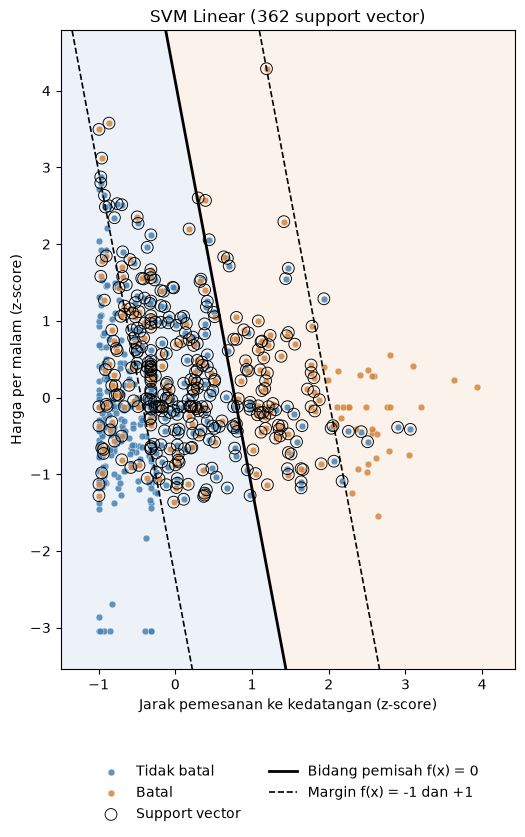

Gambar disimpan: c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\visualization\svm\svm_polynomial.png


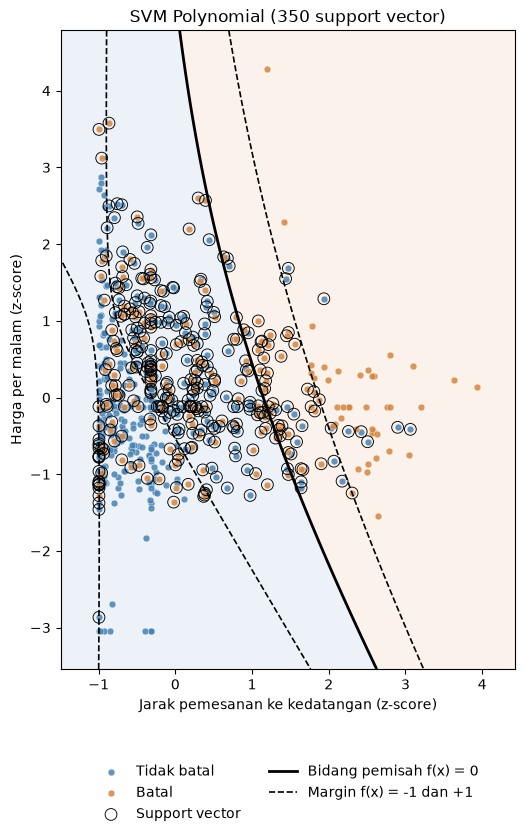

Gambar disimpan: c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\visualization\svm\svm_gaussian.png


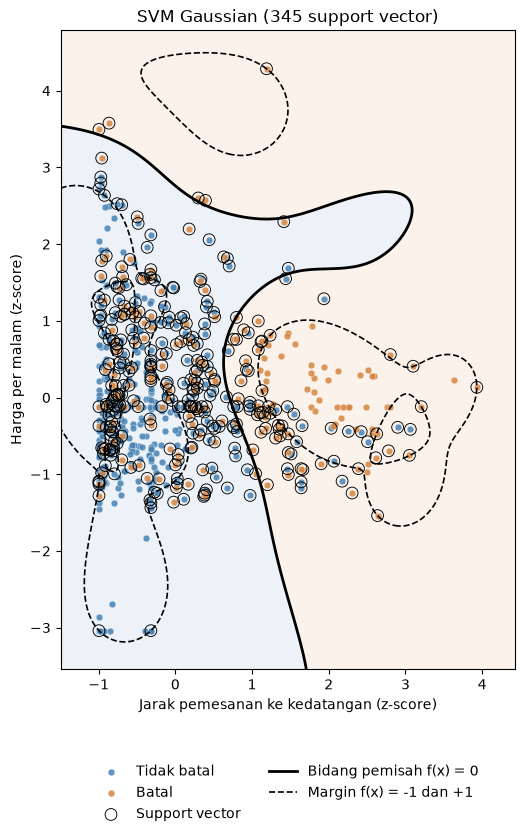

In [63]:
svm_visualization_dir = CFG.OUTPUT_DIR / 'visualization' / 'svm'
svm_visualization_dir.mkdir(parents=True, exist_ok=True)

svm_2d_min = X_svm_2d.min(axis=0) - 0.5
svm_2d_max = X_svm_2d.max(axis=0) + 0.5
svm_2d_x, svm_2d_y = np.meshgrid(
    np.linspace(svm_2d_min[0], svm_2d_max[0], 250),
    np.linspace(svm_2d_min[1], svm_2d_max[1], 250))
svm_2d_grid = np.column_stack([svm_2d_x.ravel(), svm_2d_y.ravel()])
svm_2d_colors = [CFG.PLOT_COLOR, '#d5853f']
svm_2d_names = {'linear': 'Linear', 'polynomial': 'Polynomial', 'gaussian': 'Gaussian'}

for kernel, model_2d in svm_2d_models.items():
    scores_2d = model_2d.decision_function(svm_2d_grid).reshape(svm_2d_x.shape)
    assert np.isfinite(scores_2d).all()
    assert scores_2d.min() < -1 and scores_2d.max() > 1, 'Rentang gambar belum mencakup kedua margin.'
    fig, ax = plt.subplots(figsize=(8, 8.5))
    ax.contourf(svm_2d_x, svm_2d_y, scores_2d,
                levels=[scores_2d.min() - 1, 0, scores_2d.max() + 1],
                colors=svm_2d_colors, alpha=0.10)
    for label, name, color in [(0, 'Tidak batal', svm_2d_colors[0]),
                                (1, 'Batal', svm_2d_colors[1])]:
        points = X_svm_2d[y_svm_2d == label]
        ax.scatter(points[:, 0], points[:, 1], s=24, color=color,
                   edgecolors='white', linewidths=0.3, alpha=0.85, label=name, zorder=2)
    support_2d = X_svm_2d[model_2d.support_]
    ax.scatter(support_2d[:, 0], support_2d[:, 1], s=72, facecolors='none',
               edgecolors='black', linewidths=0.65, label='Support vector', zorder=3)
    boundaries_2d = ax.contour(
        svm_2d_x, svm_2d_y, scores_2d, levels=[-1, 0, 1], colors='black',
        linestyles=['--', '-', '--'], linewidths=[1.2, 2, 1.2])
    assert all(any(len(segment) > 1 for segment in level) for level in boundaries_2d.allsegs)
    ax.plot([], [], color='black', linewidth=2, label='Bidang pemisah f(x) = 0')
    ax.plot([], [], color='black', linestyle='--', linewidth=1.2, label='Margin f(x) = -1 dan +1')
    ax.set_xlim(svm_2d_min[0], svm_2d_max[0])
    ax.set_ylim(svm_2d_min[1], svm_2d_max[1])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Jarak pemesanan ke kedatangan (z-score)')
    ax.set_ylabel('Harga per malam (z-score)')
    ax.set_title(f'SVM {svm_2d_names[kernel]} ({len(model_2d.support_)} support vector)')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
    fig.tight_layout()
    image_path_2d = svm_visualization_dir / f'svm_{kernel}.png'
    fig.savefig(image_path_2d, dpi=240, bbox_inches='tight')
    print('Gambar disimpan:', image_path_2d)
    plt.show()


**Pembahasan:**

Kernel linear menghasilkan batas berupa garis lurus. Polynomial dan Gaussian dapat menghasilkan batas melengkung. Titik dari kedua kelas masih saling bercampur pada dua fitur ini.


---

# Optimasi SVM dengan Differential Evolution (Bonus) <a name="14"></a>

Optimasi difokuskan pada kernel Gaussian yang memperoleh Macro F1 tertinggi pada percobaan awal. Parameter yang dicari adalah C untuk penalti pelanggaran margin, gamma untuk jangkauan pengaruh titik, serta ambang keputusan untuk menentukan prediksi booking batal.

[Differential Evolution, Storn dan Price (1997)](https://doi.org/10.1023/A:1008202821328) diimplementasikan dengan NumPy pada `svm.py`. Algoritma membentuk kandidat melalui mutasi dan crossover, lalu mempertahankan kandidat dengan Macro F1 CV lebih tinggi tanpa memerlukan gradien. Pencarian C dan gamma pada skala log mengacu pada [panduan Hsu, Chang, dan Lin](https://www.csie.ntu.edu.tw/~cjlin/papers/guide/guide.pdf). Pemilihan ambang mengacu pada [Lipton dkk. (2014)](https://arxiv.org/abs/1402.1892), dengan Macro F1 dihitung langsung melalui CV. Skor SVM tidak dianggap sebagai probabilitas.

Pencarian memakai 4.000 data training, tiga fold, delapan kandidat, dan empat generasi. Dua kandidat terbaik dan model awal diperiksa kembali pada 8.000 data training. Preprocessing hanya dilatih pada bagian latih setiap fold. Parameter dipilih dari CV, lalu ambang nol dan ambang hasil CV dibandingkan pada split validasi lama. Data test hanya digunakan untuk menghasilkan prediksi.


In [64]:
import warnings

svm_de_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 4000 / len(train_set)), random_state=CFG.SEED).reset_index(drop=True)

def prepare_svm_cv(data):
    labels = data[TARGET].to_numpy()
    folds = []
    for train_indices, val_indices in stratified_kfold_indices(labels, 3, CFG.SEED):
        fold_train = data.iloc[train_indices]
        fold_val = data.iloc[val_indices]
        prep = Preprocessor(feature_weights=None).fit(fold_train)
        folds.append((prep.transform(fold_train), labels[train_indices],
                      prep.transform(fold_val), labels[val_indices]))
    return folds

def score_svm_candidate(point, folds, tolerance, max_iter):
    C, gamma, threshold = 10 ** point[0], 10 ** point[1], float(point[2])
    scores = []
    for X_fold_train, y_fold_train, X_fold_val, y_fold_val in folds:
        model = SVM(C=C, kernel='gaussian', gamma=gamma, decision_threshold=threshold,
                    tol=tolerance, max_iter=max_iter)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            model.fit(X_fold_train, y_fold_train)
        if not model.converged_:
            return 0.0, 0.0, False
        scores.append(macro_f1(y_fold_val, model.predict(X_fold_val)))
    return float(np.mean(scores)), float(np.std(scores)), True

svm_de_folds = prepare_svm_cv(svm_de_data)
svm_de_history = []
def svm_de_objective(point):
    start = time.time()
    score, deviation, converged = score_svm_candidate(point, svm_de_folds, 0.01, 100000)
    svm_de_history.append({
        'evaluation': len(svm_de_history) + 1,
        'C': float(10 ** point[0]), 'gamma': float(10 ** point[1]),
        'decision_threshold': float(point[2]),
        'cv_macro_f1': score, 'cv_std': deviation,
        'converged': converged, 'seconds': time.time() - start,
    })
    print(f'Evaluasi {len(svm_de_history)}: CV Macro F1 = {score:.4f}, '
          f'konvergen = {converged}', flush=True)
    return score

svm_de_initial = np.array([np.log10(svm_models['gaussian'].C),
                           np.log10(svm_models['gaussian'].gamma_), 0.0])
print('Jumlah data pencarian:', len(svm_de_data))


Jumlah data pencarian: 4000


In [65]:
svm_de_bounds = [(-1, 2), (-3, 0), (-0.5, 0.2)]
svm_de_point, svm_de_score = differential_evolution(
    svm_de_objective, svm_de_bounds, svm_de_initial,
    population_size=8, generations=4, seed=CFG.SEED)
svm_de_trials = pd.DataFrame(svm_de_history)
assert len(svm_de_trials) == 40
assert svm_de_score >= svm_de_trials.iloc[0]['cv_macro_f1']
assert np.all(svm_de_point >= np.array(svm_de_bounds)[:, 0])
assert np.all(svm_de_point <= np.array(svm_de_bounds)[:, 1])
svm_de_trials.to_csv(CFG.OUTPUT_DIR / 'svm_optimization_history.csv', index=False)
svm_de_trials.sort_values('cv_macro_f1', ascending=False).head(5)


Evaluasi 1: CV Macro F1 = 0.7665, konvergen = True
Evaluasi 2: CV Macro F1 = 0.7344, konvergen = True
Evaluasi 3: CV Macro F1 = 0.7495, konvergen = True
Evaluasi 4: CV Macro F1 = 0.7492, konvergen = True
Evaluasi 5: CV Macro F1 = 0.7650, konvergen = True
Evaluasi 6: CV Macro F1 = 0.7620, konvergen = True
Evaluasi 7: CV Macro F1 = 0.7740, konvergen = True
Evaluasi 8: CV Macro F1 = 0.6992, konvergen = True
Evaluasi 9: CV Macro F1 = 0.7672, konvergen = True
Evaluasi 10: CV Macro F1 = 0.7496, konvergen = True
Evaluasi 11: CV Macro F1 = 0.7612, konvergen = True
Evaluasi 12: CV Macro F1 = 0.7618, konvergen = True
Evaluasi 13: CV Macro F1 = 0.6798, konvergen = True
Evaluasi 14: CV Macro F1 = 0.5857, konvergen = True
Evaluasi 15: CV Macro F1 = 0.7539, konvergen = True
Evaluasi 16: CV Macro F1 = 0.7651, konvergen = True
Generasi 1: skor terbaik = 0.7740
Evaluasi 17: CV Macro F1 = 0.7485, konvergen = True
Evaluasi 18: CV Macro F1 = 0.7782, konvergen = True
Evaluasi 19: CV Macro F1 = 0.6955, konv

,evaluation,C,gamma,decision_threshold,cv_macro_f1,cv_std,converged,seconds
34,35,3.235436,0.060966,-0.239957,0.789256,0.012686,True,8.685580
35,36,16.020070,0.060839,-0.075471,0.784192,0.013740,True,23.990674
26,27,0.851856,0.156494,-0.500000,0.782223,0.008121,True,9.467167
20,21,0.448570,0.293958,-0.500000,0.781384,0.002370,True,5.683416
17,18,7.905276,0.117114,-0.161727,0.778182,0.011576,True,16.469624


In [66]:
svm_de_shortlist = svm_de_trials[svm_de_trials['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').drop_duplicates(
        ['C', 'gamma', 'decision_threshold']).head(2)
svm_de_shortlist = pd.concat([svm_de_trials.iloc[[0]], svm_de_shortlist], ignore_index=True)
svm_de_shortlist = svm_de_shortlist.drop_duplicates(['C', 'gamma', 'decision_threshold'])
svm_de_confirmation_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 8000 / len(train_set)), random_state=CFG.SEED + 1).reset_index(drop=True)
svm_de_confirmation_folds = prepare_svm_cv(svm_de_confirmation_data)
svm_de_confirmation_rows = []
for row in svm_de_shortlist.to_dict('records'):
    point = np.array([np.log10(row['C']), np.log10(row['gamma']), row['decision_threshold']])
    score, deviation, converged = score_svm_candidate(
        point, svm_de_confirmation_folds, CFG.SVM_TOL, CFG.SVM_MAX_ITER)
    svm_de_confirmation_rows.append({
        'C': row['C'], 'gamma': row['gamma'], 'decision_threshold': row['decision_threshold'],
        'cv_macro_f1': score, 'cv_std': deviation, 'converged': converged,
    })
    print(f'Konfirmasi C={row["C"]:.4f}, gamma={row["gamma"]:.5f}, '
          f'ambang={row["decision_threshold"]:.4f}: CV Macro F1 = {score:.4f}', flush=True)
svm_de_confirmation = pd.DataFrame(svm_de_confirmation_rows)
svm_de_confirmation.to_csv(CFG.OUTPUT_DIR / 'svm_optimization_cv.csv', index=False)
svm_de_valid_candidates = svm_de_confirmation[svm_de_confirmation['converged']]
if svm_de_valid_candidates.empty:
    raise RuntimeError('Tidak ada kandidat optimasi yang konvergen pada CV konfirmasi.')
svm_de_best = svm_de_valid_candidates.sort_values('cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_de_confirmation


Konfirmasi C=1.0000, gamma=0.02857, ambang=0.0000: CV Macro F1 = 0.7738
Konfirmasi C=3.2354, gamma=0.06097, ambang=-0.2400: CV Macro F1 = 0.7983
Konfirmasi C=16.0201, gamma=0.06084, ambang=-0.0755: CV Macro F1 = 0.8021


,C,gamma,decision_threshold,cv_macro_f1,cv_std,converged
0,1.000000,0.028571,0.000000,0.773814,0.007933,True
1,3.235436,0.060966,-0.239957,0.798253,0.006814,True
2,16.020070,0.060839,-0.075471,0.802099,0.003727,True


### Evaluasi hasil optimasi

C, gamma, dan kandidat ambang dipilih melalui CV konfirmasi. Model kemudian dilatih pada seluruh training split. Ambang nol dan ambang hasil CV dibandingkan pada validasi untuk memilih aturan submission. Pembanding `SVC` memakai C, gamma, serta aturan keputusan yang sama. Karena validasi dipakai untuk memilih aturan akhir, skornya merupakan hasil pemilihan model lokal.


In [67]:
svm_de_cv_threshold = float(svm_de_best['decision_threshold'])
svm_optimized = SVM(C=float(svm_de_best['C']), kernel='gaussian',
                    gamma=float(svm_de_best['gamma']), decision_threshold=svm_de_cv_threshold,
                    tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_optimized.fit(X_svm_train, y_train)
if not svm_optimized.converged_:
    raise RuntimeError('SVM hasil optimasi belum konvergen pada training split.')
svm_optimized_scores = svm_optimized.decision_function(X_svm_val)
svm_de_zero_pred = (svm_optimized_scores >= 0).astype(int)
svm_de_cv_pred = (svm_optimized_scores >= svm_de_cv_threshold).astype(int)
if macro_f1(y_val, svm_de_zero_pred) >= macro_f1(y_val, svm_de_cv_pred):
    svm_de_submission_threshold = 0.0
else:
    svm_de_submission_threshold = svm_de_cv_threshold
svm_optimized.decision_threshold = svm_de_submission_threshold
svm_optimized_pred = svm_optimized.predict(X_svm_val)
sk_svm_optimized = SVC(C=svm_optimized.C, kernel='rbf', gamma=svm_optimized.gamma_,
                       tol=svm_optimized.tol)
sk_svm_optimized.fit(X_svm_train, y_train)
sk_svm_optimized_pred = (sk_svm_optimized.decision_function(X_svm_val)
                         >= svm_de_submission_threshold).astype(int)
svm_de_evaluation = pd.DataFrame([
    {'model': 'Gaussian awal', 'macro_f1': macro_f1(y_val, svm_val_predictions['gaussian']),
     'accuracy': accuracy(y_val, svm_val_predictions['gaussian'])},
    {'model': 'DE, ambang 0', 'macro_f1': macro_f1(y_val, svm_de_zero_pred),
     'accuracy': accuracy(y_val, svm_de_zero_pred)},
    {'model': 'DE, ambang CV', 'macro_f1': macro_f1(y_val, svm_de_cv_pred),
     'accuracy': accuracy(y_val, svm_de_cv_pred)},
    {'model': 'SVC, ambang terpilih', 'macro_f1': macro_f1(y_val, sk_svm_optimized_pred),
     'accuracy': accuracy(y_val, sk_svm_optimized_pred)},
])
svm_de_gain = macro_f1(y_val, svm_optimized_pred) - macro_f1(y_val, svm_val_predictions['gaussian'])
print(f'Ambang untuk submission: {svm_de_submission_threshold:.4f}')
print(f'Perubahan Macro F1 validasi: {svm_de_gain:+.4f}')
print(f'Kesamaan prediksi dengan SVC: {np.mean(svm_optimized_pred == sk_svm_optimized_pred):.2%}')
svm_optimized.save(CFG.MODEL_DIR / 'svm_optimized.pkl')
svm_preprocessor.save(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
loaded_svm_optimized = SVM.load(CFG.MODEL_DIR / 'svm_optimized.pkl')
loaded_svm_optimized_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
assert np.array_equal(loaded_svm_optimized.predict(loaded_svm_optimized_prep.transform(val_set)),
                      svm_optimized_pred)
svm_de_evaluation


Ambang untuk submission: 0.0000
Perubahan Macro F1 validasi: +0.0311
Kesamaan prediksi dengan SVC: 100.00%


,model,macro_f1,accuracy
0,Gaussian awal,0.793290,0.826667
1,"DE, ambang 0",0.824396,0.848584
2,"DE, ambang CV",0.821070,0.844566
3,"SVC, ambang terpilih",0.824396,0.848584


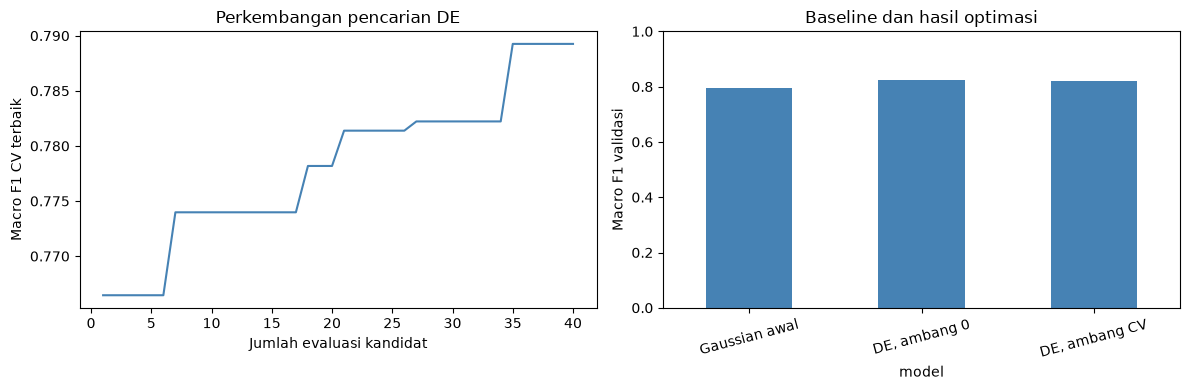

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(svm_de_trials['evaluation'], svm_de_trials['cv_macro_f1'].cummax(), color=CFG.PLOT_COLOR)
axes[0].set_xlabel('Jumlah evaluasi kandidat')
axes[0].set_ylabel('Macro F1 CV terbaik')
axes[0].set_title('Perkembangan pencarian DE')
svm_de_evaluation.iloc[:3].plot.bar(x='model', y='macro_f1', ax=axes[1],
                                  color=CFG.PLOT_COLOR, legend=False)
axes[1].set_ylabel('Macro F1 validasi')
axes[1].set_title('Baseline dan hasil optimasi')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()


In [69]:
svm_optimized_final_preprocessor = Preprocessor(feature_weights=None).fit(full_train)
svm_optimized_final = SVM(C=svm_optimized.C, kernel='gaussian', gamma=svm_optimized.gamma,
                          decision_threshold=svm_optimized.decision_threshold,
                          tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_optimized_final.fit(svm_optimized_final_preprocessor.transform(full_train),
                        full_train[TARGET].to_numpy())
if not svm_optimized_final.converged_:
    raise RuntimeError('SVM final hasil optimasi belum konvergen.')
svm_optimized_test_pred = svm_optimized_final.predict(svm_optimized_final_preprocessor.transform(test_df))
svm_optimized_submission = pd.DataFrame({'id': test_df['id'],
                                        'is_canceled': svm_optimized_test_pred.astype(int)})
assert svm_optimized_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_optimized_submission['id'].equals(sample_submission['id'])
assert len(svm_optimized_submission) == len(test_df) and svm_optimized_submission['id'].is_unique
assert set(svm_optimized_submission['is_canceled'].unique()) <= {0, 1}
svm_optimized_submission_path = CFG.OUTPUT_DIR / 'submission_svm_optimized.csv'
svm_optimized_submission.to_csv(svm_optimized_submission_path, index=False)
svm_optimized_final.save(CFG.MODEL_DIR / 'svm_optimized_final.pkl')
svm_optimized_final_preprocessor.save(CFG.MODEL_DIR / 'svm_optimized_preprocessor_final.pkl')
print(svm_optimized_submission_path, svm_optimized_submission.shape)
svm_optimized_submission.head()


c:\Users\Kalyca\Desktop\AI\IF3170_G25_IMKSIAI\output\submission_svm_optimized.csv (6844, 2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


**Pembahasan:**

Pencarian awal menaikkan Macro F1 CV dari 0,7665 menjadi 0,7893. Pada CV konfirmasi, baseline memperoleh 0,7738 dan kandidat terpilih memperoleh 0,8021. Parameter yang terpilih adalah C sekitar 16,02 dan gamma sekitar 0,06084.

Pada validasi, parameter DE dengan ambang nol memperoleh Macro F1 0,8242, dibandingkan baseline 0,7933. Ambang hasil CV sebesar -0,07547 memperoleh 0,8211. Ambang nol dipakai untuk submission karena menghasilkan skor validasi yang lebih tinggi. Percobaan ini menunjukkan bahwa perubahan ambang tidak selalu membantu pada data lain.


---

# Optimasi Lanjutan SVM (Bonus) <a name="15"></a>

Optimasi ini menguji representasi fitur, pembobotan fitur dan kelas, serta parameter C dan gamma.Differential Evolution mencari kombinasi parameter melalui mutasi, crossover, dan seleksi berdasarkan Macro F1 CV. Sebanyak 32 kandidat dievaluasi menggunakan tiga fold pada 8.000 data training. Preprocessing hanya dilatih pada bagian latih setiap fold.

Kandidat terbaik diperhalus melalui pencarian lokal, lalu dibandingkan dengan model sebelumnya menggunakan CV pada seluruh training split. Model dipilih berdasarkan Macro F1 CV dengan ambang keputusan nol. Validasi lama digunakan untuk pelaporan hasil sehingga belum menjadi evaluasi independen.

In [70]:
svm_refine_feature_options = {
    'Awal': None,
    'Log riwayat': dict(log_history=True, binary_unscaled=False, date_encoding='original'),
    'Biner 0/1': dict(log_history=False, binary_unscaled=True, date_encoding='original'),
    'Log dan biner': dict(log_history=True, binary_unscaled=True, date_encoding='original'),
    'Tanggal ordinal': dict(log_history=True, binary_unscaled=True, date_encoding='ordinal'),
    'Tanggal siklik': dict(log_history=True, binary_unscaled=True, date_encoding='cyclical'),
}
svm_refine_base_parameters = {'C': float(svm_optimized.C), 'gamma': float(svm_optimized.gamma_)}

def make_svm_refine_preprocessor(features):
    if features == 'Bobot fitur':
        return Preprocessor(feature_weights=CFG.FEATURE_WEIGHTS)
    options = svm_refine_feature_options[features]
    if options is None:
        return Preprocessor(feature_weights=None)
    return SVMPreprocessor(**options)

def prepare_svm_refine_folds(data, features, seed=CFG.SEED):
    labels = data[TARGET].to_numpy()
    folds = []
    for train_indices, val_indices in stratified_kfold_indices(labels, 3, seed):
        prep = make_svm_refine_preprocessor(features).fit(data.iloc[train_indices])
        folds.append((prep.transform(data.iloc[train_indices]), labels[train_indices],
                      prep.transform(data.iloc[val_indices]), labels[val_indices], val_indices))
    return folds

def evaluate_svm_refine(C, gamma, weight, folds, tolerance=0.005):
    scores = []
    oof = np.empty(sum(len(fold[3]) for fold in folds))
    for X_fit, y_fit, X_check, y_check, indices in folds:
        model = SVM(C=float(C), kernel='gaussian', gamma=float(gamma),
                    class_weight={0: 1.0, 1: float(weight)}, tol=tolerance,
                    max_iter=CFG.SVM_MAX_ITER)
        model.fit(X_fit, y_fit)
        if not model.converged_:
            return dict(cv_macro_f1=0.0, cv_std=0.0, converged=False), None
        oof[indices] = model.decision_function(X_check)
        scores.append(macro_f1(y_check, (oof[indices] >= 0).astype(int)))
        labels = 2 * y_fit - 1
        assert np.all(model.alpha_ >= 0) and np.all(model.alpha_ <= model.C_)
        assert abs(model.alpha_ @ labels) < 1e-6
    return dict(cv_macro_f1=float(np.mean(scores)), cv_std=float(np.std(scores)),
                converged=True), oof

svm_refine_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 8000 / len(train_set)), random_state=CFG.SEED + 2).reset_index(drop=True)
svm_refine_fold_cache = {}
print('Data pencarian lanjutan:', len(svm_refine_data))

Data pencarian lanjutan: 8000


In [71]:
svm_refine_feature_rows = []
for features in svm_refine_feature_options:
    start = time.time()
    folds = prepare_svm_refine_folds(svm_refine_data, features)
    svm_refine_fold_cache[features] = folds
    result, _ = evaluate_svm_refine(**svm_refine_base_parameters, weight=1.0, folds=folds)
    svm_refine_feature_rows.append(dict(features=features, **result, seconds=time.time() - start))
    print(f'{features}: CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_features = pd.DataFrame(svm_refine_feature_rows)
svm_refine_features.sort_values('cv_macro_f1', ascending=False)

Awal: CV Macro F1 = 0.8091
Log riwayat: CV Macro F1 = 0.8091
Biner 0/1: CV Macro F1 = 0.8085
Log dan biner: CV Macro F1 = 0.8086
Tanggal ordinal: CV Macro F1 = 0.8002
Tanggal siklik: CV Macro F1 = 0.8057


,features,cv_macro_f1,cv_std,converged,seconds
0,Awal,0.809082,0.003988,True,66.470421
1,Log riwayat,0.809082,0.004110,True,69.440173
3,Log dan biner,0.808591,0.004356,True,72.184127
2,Biner 0/1,0.808542,0.005053,True,71.971679
5,Tanggal siklik,0.805726,0.003683,True,71.676971
4,Tanggal ordinal,0.800244,0.002166,True,60.212491


In [72]:
svm_refine_short_features = svm_refine_features[svm_refine_features['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').head(2)['features'].tolist()
svm_refine_weight_rows = []
for features in svm_refine_short_features:
    folds = svm_refine_fold_cache[features]
    for weight in [1.0, 1.25, 1.5, 2.0]:
        start = time.time()
        if weight == 1.0:
            previous = svm_refine_features[svm_refine_features['features'] == features].iloc[0]
            result = dict(cv_macro_f1=previous['cv_macro_f1'],
                          cv_std=previous['cv_std'], converged=bool(previous['converged']))
        else:
            result, _ = evaluate_svm_refine(**svm_refine_base_parameters, weight=weight, folds=folds)
        svm_refine_weight_rows.append(dict(features=features, **svm_refine_base_parameters,
                                           weight=weight, **result, seconds=time.time() - start))
        print(f'{features}, bobot {weight}: CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_weights = pd.DataFrame(svm_refine_weight_rows)
svm_refine_weights.sort_values('cv_macro_f1', ascending=False)

Awal, bobot 1.0: CV Macro F1 = 0.8091
Awal, bobot 1.25: CV Macro F1 = 0.8086
Awal, bobot 1.5: CV Macro F1 = 0.8059
Awal, bobot 2.0: CV Macro F1 = 0.7982
Log riwayat, bobot 1.0: CV Macro F1 = 0.8091
Log riwayat, bobot 1.25: CV Macro F1 = 0.8086
Log riwayat, bobot 1.5: CV Macro F1 = 0.8059
Log riwayat, bobot 2.0: CV Macro F1 = 0.7982


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
0,Awal,16.02007,0.060839,1.00,0.809082,0.003988,True,0.002943
4,Log riwayat,16.02007,0.060839,1.00,0.809082,0.004110,True,0.002241
1,Awal,16.02007,0.060839,1.25,0.808571,0.001486,True,74.159459
5,Log riwayat,16.02007,0.060839,1.25,0.808571,0.001512,True,72.489175
6,Log riwayat,16.02007,0.060839,1.50,0.805869,0.001957,True,79.204370
2,Awal,16.02007,0.060839,1.50,0.805869,0.001957,True,80.066975
3,Awal,16.02007,0.060839,2.00,0.798159,0.001959,True,84.774717
7,Log riwayat,16.02007,0.060839,2.00,0.798159,0.001959,True,82.079263


In [73]:
svm_refine_seed = svm_refine_weights[svm_refine_weights['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_search_features = svm_refine_seed['features']
svm_refine_search_folds = svm_refine_fold_cache[svm_refine_search_features]
svm_refine_result_cache = {}
for row in svm_refine_weights[svm_refine_weights['features'] == svm_refine_search_features].to_dict('records'):
    key = tuple(round(row[name], 12) for name in ['C', 'gamma', 'weight'])
    svm_refine_result_cache[key] = {name: row[name] for name in ['cv_macro_f1', 'cv_std', 'converged']}
svm_refine_search_rows = []

def svm_refine_objective(point):
    C, gamma, weight = float(10 ** point[0]), float(10 ** point[1]), float(point[2])
    key = tuple(round(value, 12) for value in [C, gamma, weight])
    start = time.time()
    cached = key in svm_refine_result_cache
    if not cached:
        result, _ = evaluate_svm_refine(C, gamma, weight, svm_refine_search_folds)
        svm_refine_result_cache[key] = result
    result = svm_refine_result_cache[key]
    svm_refine_search_rows.append(dict(evaluation=len(svm_refine_search_rows) + 1,
        features=svm_refine_search_features, C=C, gamma=gamma, weight=weight,
        **result, cached=cached, seconds=time.time() - start))
    print(f'Evaluasi lanjutan {len(svm_refine_search_rows)}: '
          f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
    return float(result['cv_macro_f1'])

svm_refine_bounds = [(np.log10(4), np.log10(64)), (np.log10(0.01), np.log10(0.2)), (0.75, 2.0)]
svm_refine_start = np.array([np.log10(svm_refine_seed['C']),
                             np.log10(svm_refine_seed['gamma']), svm_refine_seed['weight']])
svm_refine_point, svm_refine_score = differential_evolution(
    svm_refine_objective, bounds=svm_refine_bounds,
    initial_point=np.clip(svm_refine_start, [b[0] for b in svm_refine_bounds], [b[1] for b in svm_refine_bounds]), population_size=8, generations=3, seed=CFG.SEED + 2)
svm_refine_search = pd.DataFrame(svm_refine_search_rows)
svm_refine_search.sort_values('cv_macro_f1', ascending=False).head(8)

Evaluasi lanjutan 1: CV Macro F1 = 0.8091
Evaluasi lanjutan 2: CV Macro F1 = 0.7960
Evaluasi lanjutan 3: CV Macro F1 = 0.7947
Evaluasi lanjutan 4: CV Macro F1 = 0.7790
Evaluasi lanjutan 5: CV Macro F1 = 0.7725
Evaluasi lanjutan 6: CV Macro F1 = 0.8031
Evaluasi lanjutan 7: CV Macro F1 = 0.7909
Evaluasi lanjutan 8: CV Macro F1 = 0.7973
Evaluasi lanjutan 9: CV Macro F1 = 0.7919
Evaluasi lanjutan 10: CV Macro F1 = 0.7966
Evaluasi lanjutan 11: CV Macro F1 = 0.7703
Evaluasi lanjutan 12: CV Macro F1 = 0.7980
Evaluasi lanjutan 13: CV Macro F1 = 0.8023
Evaluasi lanjutan 14: CV Macro F1 = 0.7891
Evaluasi lanjutan 15: CV Macro F1 = 0.7969
Evaluasi lanjutan 16: CV Macro F1 = 0.7888
Generasi 1: skor terbaik = 0.8091
Evaluasi lanjutan 17: CV Macro F1 = 0.8044
Evaluasi lanjutan 18: CV Macro F1 = 0.7959
Evaluasi lanjutan 19: CV Macro F1 = 0.7845
Evaluasi lanjutan 20: CV Macro F1 = 0.7895
Evaluasi lanjutan 21: CV Macro F1 = 0.7952
Evaluasi lanjutan 22: CV Macro F1 = 0.7912
Evaluasi lanjutan 23: CV Macr

,evaluation,features,C,gamma,weight,cv_macro_f1,cv_std,converged,cached,seconds
0,1,Awal,16.020070,0.060839,1.000000,0.809082,0.003988,True,True,0.000011
16,17,Awal,29.037306,0.056972,1.000000,0.804375,0.003625,True,False,65.513630
5,6,Awal,4.221771,0.109003,1.875944,0.803055,0.003039,True,False,37.978897
12,13,Awal,19.177836,0.059770,1.744428,0.802344,0.002441,True,False,71.465461
29,30,Awal,4.000000,0.093223,2.000000,0.802213,0.002376,True,False,46.256170
24,25,Awal,18.367575,0.087187,1.000000,0.801987,0.004206,True,False,81.707798
27,28,Awal,4.000000,0.065610,2.000000,0.801276,0.001885,True,False,37.567792
30,31,Awal,4.000000,0.068487,2.000000,0.801105,0.002235,True,False,34.379253


In [74]:
svm_refine_metric_folds = prepare_svm_refine_folds(svm_refine_data, 'Bobot fitur')
svm_refine_fold_cache['Bobot fitur'] = svm_refine_metric_folds
svm_refine_metric_rows = []
for C_factor in [0.5, 1.0, 2.0]:
    for gamma_factor in [0.5, 1.0]:
        C = svm_refine_base_parameters['C'] * C_factor
        gamma = svm_refine_base_parameters['gamma'] * gamma_factor
        start = time.time()
        result, _ = evaluate_svm_refine(C, gamma, 1.0, svm_refine_metric_folds)
        svm_refine_metric_rows.append(dict(features='Bobot fitur', C=C, gamma=gamma,
                                           weight=1.0, **result, seconds=time.time() - start))
        print(f'Bobot fitur, C={C:.3f}, gamma={gamma:.5f}: '
              f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_metric = pd.DataFrame(svm_refine_metric_rows)
svm_refine_metric_fixed = svm_refine_metric[
    (svm_refine_metric['C'] == svm_refine_base_parameters['C']) &
    (svm_refine_metric['gamma'] == svm_refine_base_parameters['gamma'])][svm_refine_features.columns]
svm_refine_features = pd.concat([
    svm_refine_features[svm_refine_features['features'] != 'Bobot fitur'],
    svm_refine_metric_fixed], ignore_index=True)
svm_refine_metric.sort_values('cv_macro_f1', ascending=False)

Bobot fitur, C=8.010, gamma=0.03042: CV Macro F1 = 0.8075
Bobot fitur, C=8.010, gamma=0.06084: CV Macro F1 = 0.8174
Bobot fitur, C=16.020, gamma=0.03042: CV Macro F1 = 0.8101
Bobot fitur, C=16.020, gamma=0.06084: CV Macro F1 = 0.8132
Bobot fitur, C=32.040, gamma=0.03042: CV Macro F1 = 0.8131
Bobot fitur, C=32.040, gamma=0.06084: CV Macro F1 = 0.8047


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
1,Bobot fitur,8.010035,0.060839,1.0,0.817353,0.007404,True,52.663378
3,Bobot fitur,16.020070,0.060839,1.0,0.813236,0.006360,True,44.677649
4,Bobot fitur,32.040140,0.030420,1.0,0.813076,0.004005,True,99.671831
2,Bobot fitur,16.020070,0.030420,1.0,0.810053,0.006759,True,55.824353
0,Bobot fitur,8.010035,0.030420,1.0,0.807508,0.009870,True,50.678651
5,Bobot fitur,32.040140,0.060839,1.0,0.804712,0.007466,True,67.860326


In [75]:
svm_refine_local_candidates = pd.concat([svm_refine_search, svm_refine_metric], ignore_index=True)
svm_refine_center = svm_refine_local_candidates[svm_refine_local_candidates['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_local_features = svm_refine_center['features']
if svm_refine_local_features not in svm_refine_fold_cache:
    svm_refine_fold_cache[svm_refine_local_features] = prepare_svm_refine_folds(
        svm_refine_data, svm_refine_local_features)
svm_refine_local_rows = []
for C_factor in [0.5, 1.0, 2.0]:
    for gamma_factor in [0.7, 1.0, 1.4]:
        C = float(svm_refine_center['C'] * C_factor)
        gamma = float(svm_refine_center['gamma'] * gamma_factor)
        weight = float(svm_refine_center['weight'])
        start = time.time()
        previous = svm_refine_local_candidates[
            (svm_refine_local_candidates['features'] == svm_refine_local_features) &
            np.isclose(svm_refine_local_candidates['C'], C, rtol=1e-12, atol=0) &
            np.isclose(svm_refine_local_candidates['gamma'], gamma, rtol=1e-12, atol=0) &
            np.isclose(svm_refine_local_candidates['weight'], weight, rtol=1e-12, atol=0)]
        if len(previous):
            result = {name: previous.iloc[0][name] for name in ['cv_macro_f1', 'cv_std', 'converged']}
        else:
            result, _ = evaluate_svm_refine(C, gamma, weight,
                                           svm_refine_fold_cache[svm_refine_local_features])
        svm_refine_local_rows.append(dict(features=svm_refine_local_features, C=C, gamma=gamma,
                                          weight=weight, **result, seconds=time.time() - start))
        print(f'Pencarian lokal C={C:.3f}, gamma={gamma:.5f}: '
              f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_local = pd.DataFrame(svm_refine_local_rows)
svm_refine_local.sort_values('cv_macro_f1', ascending=False)

Pencarian lokal C=4.005, gamma=0.04259: CV Macro F1 = 0.8079
Pencarian lokal C=4.005, gamma=0.06084: CV Macro F1 = 0.8149
Pencarian lokal C=4.005, gamma=0.08517: CV Macro F1 = 0.8166
Pencarian lokal C=8.010, gamma=0.04259: CV Macro F1 = 0.8135
Pencarian lokal C=8.010, gamma=0.06084: CV Macro F1 = 0.8174
Pencarian lokal C=8.010, gamma=0.08517: CV Macro F1 = 0.8109
Pencarian lokal C=16.020, gamma=0.04259: CV Macro F1 = 0.8166
Pencarian lokal C=16.020, gamma=0.06084: CV Macro F1 = 0.8132
Pencarian lokal C=16.020, gamma=0.08517: CV Macro F1 = 0.8060


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
4,Bobot fitur,8.010035,0.060839,1.0,0.817353,0.007404,True,0.002792
2,Bobot fitur,4.005018,0.085175,1.0,0.816608,0.009605,True,35.635692
6,Bobot fitur,16.020070,0.042587,1.0,0.816604,0.005234,True,79.444018
1,Bobot fitur,4.005018,0.060839,1.0,0.814916,0.006249,True,57.113743
3,Bobot fitur,8.010035,0.042587,1.0,0.813511,0.006108,True,48.799671
7,Bobot fitur,16.020070,0.060839,1.0,0.813236,0.006360,True,0.003402
5,Bobot fitur,8.010035,0.085175,1.0,0.810879,0.007781,True,55.139246
0,Bobot fitur,4.005018,0.042587,1.0,0.807871,0.009701,True,43.698265
8,Bobot fitur,16.020070,0.085175,1.0,0.806033,0.010326,True,3484.458520


In [76]:
svm_refine_all_search = pd.concat([svm_refine_search, svm_refine_metric, svm_refine_local], ignore_index=True)
svm_refine_all_search = svm_refine_all_search[svm_refine_all_search['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable')
svm_refine_top_search = svm_refine_all_search.loc[
    ~svm_refine_all_search[['features', 'C', 'gamma', 'weight']].round(10).duplicated()].head(2)
svm_refine_best_features = svm_refine_features[svm_refine_features['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]['features']
svm_refine_shortlist = pd.DataFrame([
    dict(features='Awal', **svm_refine_base_parameters, weight=1.0),
    dict(features=svm_refine_best_features, **svm_refine_base_parameters, weight=1.0),
    {name: svm_refine_seed[name] for name in ['features', 'C', 'gamma', 'weight']},
])
svm_refine_shortlist = pd.concat(
    [svm_refine_shortlist, svm_refine_top_search[['features', 'C', 'gamma', 'weight']]],
    ignore_index=True)
svm_refine_shortlist = svm_refine_shortlist.loc[
    ~svm_refine_shortlist[['features', 'C', 'gamma', 'weight']].round(10).duplicated()]
svm_refine_confirmation_cache = {}
svm_refine_confirmation_rows = []
for row in svm_refine_shortlist.to_dict('records'):
    start = time.time()
    features = row['features']
    if features not in svm_refine_confirmation_cache:
        svm_refine_confirmation_cache[features] = prepare_svm_refine_folds(
            train_set, features, seed=CFG.SEED + 3)
    folds = svm_refine_confirmation_cache[features]
    result, oof = evaluate_svm_refine(row['C'], row['gamma'], row['weight'],
                                     folds, tolerance=CFG.SVM_TOL)
    svm_refine_confirmation_rows.append(dict(**row, **result, seconds=time.time() - start))
    print(f'CV seluruh training: {features}, C={row["C"]:.4f}, gamma={row["gamma"]:.5f}, '
          f'bobot={row["weight"]:.3f}: {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_confirmation = pd.DataFrame(svm_refine_confirmation_rows)
svm_refine_candidates = svm_refine_confirmation[svm_refine_confirmation['converged']]
if svm_refine_candidates.empty:
    raise RuntimeError('Tidak ada kandidat lanjutan yang konvergen pada CV seluruh training.')
svm_refine_best = svm_refine_candidates.sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_confirmation.sort_values('cv_macro_f1', ascending=False)

CV seluruh training: Awal, C=16.0201, gamma=0.06084, bobot=1.000: 0.8211
CV seluruh training: Bobot fitur, C=16.0201, gamma=0.06084, bobot=1.000: 0.8249
CV seluruh training: Bobot fitur, C=8.0100, gamma=0.06084, bobot=1.000: 0.8229
CV seluruh training: Bobot fitur, C=4.0050, gamma=0.08517, bobot=1.000: 0.8243


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
1,Bobot fitur,16.020070,0.060839,1.0,0.824924,0.006095,True,687.467367
3,Bobot fitur,4.005018,0.085175,1.0,0.824275,0.006020,True,150.591935
2,Bobot fitur,8.010035,0.060839,1.0,0.822924,0.007991,True,242.647331
0,Awal,16.020070,0.060839,1.0,0.821069,0.006272,True,21867.548973


In [77]:
svm_refined_preprocessor = make_svm_refine_preprocessor(svm_refine_best['features']).fit(train_set)
svm_refined = SVM(C=float(svm_refine_best['C']), kernel='gaussian',
                  gamma=float(svm_refine_best['gamma']),
                  class_weight={0: 1.0, 1: float(svm_refine_best['weight'])},
                  tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_refined.fit(svm_refined_preprocessor.transform(train_set), train_set[TARGET].to_numpy())
if not svm_refined.converged_:
    raise RuntimeError('SVM lanjutan belum konvergen pada training split.')
svm_refined_val_pred = svm_refined.predict(svm_refined_preprocessor.transform(val_set))
svm_refine_old_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
svm_refine_old_pred = svm_optimized.predict(svm_refine_old_prep.transform(val_set))
svm_refine_validation_rows = []
for name, pred in [('Optimasi sebelumnya', svm_refine_old_pred), ('Optimasi lanjutan', svm_refined_val_pred)]:
    f1_scores = f1_per_class(val_set[TARGET].to_numpy(), pred)
    svm_refine_validation_rows.append(dict(model=name,
        macro_f1=macro_f1(val_set[TARGET].to_numpy(), pred),
        accuracy=accuracy(val_set[TARGET].to_numpy(), pred),
        f1_tidak_batal=f1_scores[0], f1_batal=f1_scores[1]))
svm_refine_validation = pd.DataFrame(svm_refine_validation_rows)
svm_refined.save(CFG.MODEL_DIR / 'svm_refined.pkl')
svm_refined_preprocessor.save(CFG.MODEL_DIR / 'svm_refined_preprocessor.pkl')
svm_refine_loaded = SVM.load(CFG.MODEL_DIR / 'svm_refined.pkl')
svm_refine_loaded_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_refined_preprocessor.pkl')
assert np.array_equal(svm_refine_loaded.predict(svm_refine_loaded_prep.transform(val_set)),
                      svm_refined_val_pred)
print('Konfigurasi terpilih dari CV:', svm_refine_best[['features', 'C', 'gamma', 'weight']].to_dict())
svm_refine_validation

Konfigurasi terpilih dari CV: {'features': 'Bobot fitur', 'C': 16.020070145041014, 'gamma': 0.06083922985629342, 'weight': 1.0}


,model,macro_f1,accuracy,f1_tidak_batal,f1_batal
0,Optimasi sebelumnya,0.824396,0.848584,0.889570,0.759222
1,Optimasi lanjutan,0.826259,0.850594,0.891281,0.761238


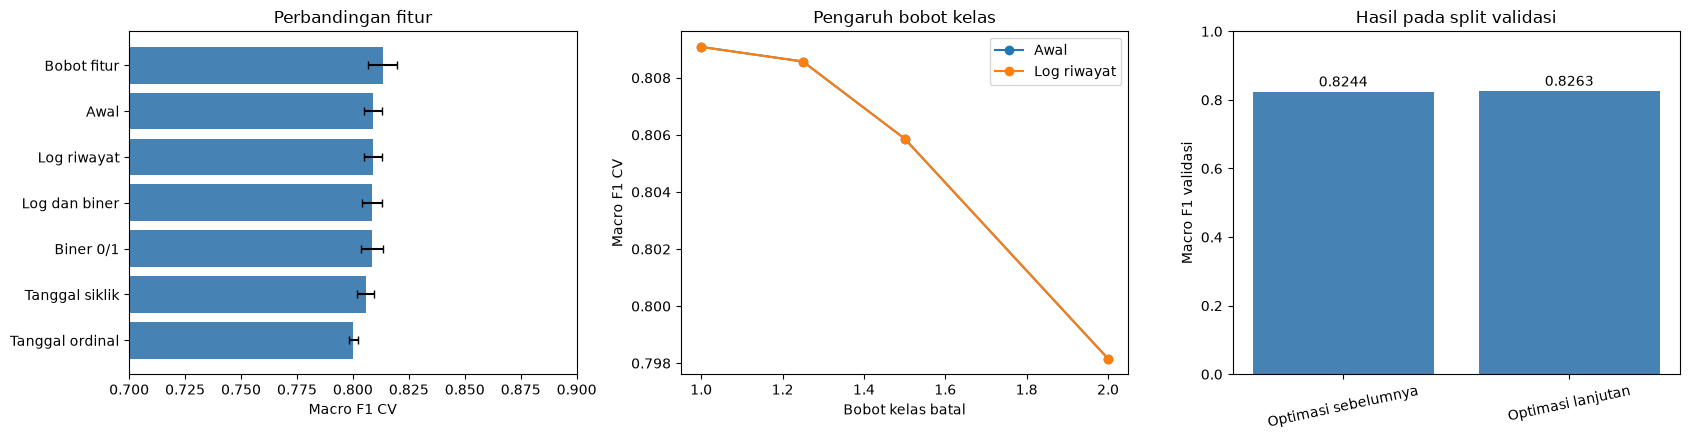

In [78]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
feature_plot = svm_refine_features.sort_values('cv_macro_f1')
axes[0].barh(feature_plot['features'], feature_plot['cv_macro_f1'],
             xerr=feature_plot['cv_std'], color=CFG.PLOT_COLOR, capsize=3)
axes[0].set(xlabel='Macro F1 CV', title='Perbandingan fitur', xlim=(0.7, 0.9))
for features, rows in svm_refine_weights.groupby('features', sort=False):
    rows = rows.sort_values('weight')
    axes[1].plot(rows['weight'], rows['cv_macro_f1'], marker='o', label=features)
axes[1].set(xlabel='Bobot kelas batal', ylabel='Macro F1 CV', title='Pengaruh bobot kelas')
axes[1].legend()
axes[2].bar(svm_refine_validation['model'], svm_refine_validation['macro_f1'], color=CFG.PLOT_COLOR)
axes[2].set(ylabel='Macro F1 validasi', title='Hasil pada split validasi', ylim=(0, 1))
axes[2].tick_params(axis='x', labelrotation=12)
for index, score in enumerate(svm_refine_validation['macro_f1']):
    axes[2].text(index, score + 0.015, f'{score:.4f}', ha='center')
fig.tight_layout()
plt.show()

In [ ]:
svm_refined_final_preprocessor = make_svm_refine_preprocessor(svm_refine_best['features']).fit(full_train)
svm_refined_final = SVM(C=svm_refined.C, kernel='gaussian', gamma=svm_refined.gamma,
                        class_weight=svm_refined.class_weight, decision_threshold=0.0,
                        tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_refined_final.fit(svm_refined_final_preprocessor.transform(full_train),
                      full_train[TARGET].to_numpy())
if not svm_refined_final.converged_:
    raise RuntimeError('SVM final lanjutan belum konvergen.')
svm_refined_test_pred = svm_refined_final.predict(svm_refined_final_preprocessor.transform(test_df))
svm_refined_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': svm_refined_test_pred.astype(int)})
assert svm_refined_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_refined_submission['id'].equals(sample_submission['id'])
assert len(svm_refined_submission) == len(test_df) and svm_refined_submission['id'].is_unique
assert set(svm_refined_submission['is_canceled'].unique()) <= {0, 1}
svm_refined_submission_path = CFG.OUTPUT_DIR / 'submission_svm_refined.csv'
svm_refined_submission.to_csv(svm_refined_submission_path, index=False)
svm_refined_final.save(CFG.MODEL_DIR / 'svm_refined_final.pkl')
svm_refined_final_preprocessor.save(CFG.MODEL_DIR / 'svm_refined_preprocessor_final.pkl')
svm_refine_final_loaded = SVM.load(CFG.MODEL_DIR / 'svm_refined_final.pkl')
svm_refine_final_prep_loaded = Preprocessor.load(CFG.MODEL_DIR / 'svm_refined_preprocessor_final.pkl')
assert np.array_equal(svm_refine_final_loaded.predict(svm_refine_final_prep_loaded.transform(test_df)),
                      svm_refined_test_pred)
print(svm_refined_submission_path, svm_refined_submission.shape)
svm_refined_submission.head()

**Hasil dan pembahasan:**

CV pada seluruh training split memilih pembobotan fitur dengan C sekitar 16.02, gamma 0.06084, bobot kelas batal 1, dan ambang keputusan nol. Macro F1 CV naik dari 0.8211 menjadi 0.8249. Pada split validasi lama, Macro F1 naik dari 0.8242 menjadi 0.8264, dengan selisih +0.0022.

Peningkatan berasal dari pembobotan fitur. Transformasi log riwayat dan fitur biner 0/1 belum memberi peningkatan yang konsisten pada parameter awal. Penggantian representasi tanggal dan bobot kelas yang lebih besar menurunkan CV pada percobaan tersebut. Pencarian DE lanjutan juga belum melampaui konfigurasi sebelumnya, sedangkan pembobotan fitur menghasilkan kandidat yang lebih baik.

Model terpilih dilatih ulang pada seluruh data training yang sudah dibersihkan.CV digunakan untuk pemilihan konfigurasi. Split validasi sudah pernah digunakan sebelumnya, sehingga hasil ini belum menjadi estimasi independen. Skor leaderboard submission baru belum diketahui.

---

# Optimasi Naive Bayes dengan Particle Swarm Optimization (Bonus) <a name="16"></a>

[Particle Swarm Optimization, Kennedy dan Eberhart (1995)](https://doi.org/10.1109/ICNN.1995.488968) diimplementasikan dengan NumPy pada `naive_bayes.py`. Setiap partikel mewakili kandidat parameter. Kecepatannya diperbarui dari arah sebelumnya, posisi terbaiknya sendiri, dan posisi terbaik kelompok, menggunakan inertia seperti pada [Shi dan Eberhart (1998)](https://doi.org/10.1007/BFb0040810).

Parameter yang dicari adalah jumlah bin (5-80, dibulatkan), log10(alpha) (-3 sampai 1), dan ambang prediksi batal (0,2-0,8). Jumlah bin mengatur rincian atribut numerik, alpha mengatur smoothing, dan ambang mengatur keputusan kelas. Pencarian ambang mengacu pada [Lipton dkk. (2014)](https://arxiv.org/abs/1402.1892); Macro F1 dihitung langsung melalui CV tanpa mengasumsikan probabilitas model terkalibrasi.

Pencarian memakai 12 partikel dan 12 iterasi dengan seed 42, inertia 0,7, serta koefisien personal dan sosial masing-masing 1,5. Kecepatan dibatasi 20% rentang tiap parameter dan posisi dibatasi ruang pencarian. Nilai ini ditetapkan sebelum evaluasi validasi. Model awal disertakan sebagai kandidat pertama. Seluruh kandidat dinilai pada 5 fold training yang sama dengan baseline, dengan preprocessing di-fit ulang dalam setiap fold. Validasi hanya untuk pelaporan, bukan pemilihan parameter; test hanya untuk submission.

In [ ]:
from functools import lru_cache
from naive_bayes import particle_swarm_optimization

nb_pso_indices = list(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED))

@lru_cache(maxsize=4)
def prepare_nb_pso_folds(n_bins):
    folds = []
    for tr_idx, va_idx in nb_pso_indices:
        prep = NaiveBayesPreprocessor(n_bins=n_bins).fit(train_set.iloc[tr_idx])
        folds.append((prep.transform(train_set.iloc[tr_idx]), y_train[tr_idx],
                      prep.transform(train_set.iloc[va_idx]), y_train[va_idx],
                      prep.n_categories_.copy()))
    return folds

def decode_nb_pso(point):
    return int(np.rint(point[0])), float(10 ** point[1]), float(point[2])

nb_pso_history = []
nb_pso_cache = {}

def nb_pso_objective(point):
    bins, alpha, threshold = decode_nb_pso(point)
    key = (bins, alpha, threshold)
    cached = key in nb_pso_cache
    if not cached:
        scores = []
        for X_fit, y_fit, X_check, y_check, categories in prepare_nb_pso_folds(bins):
            model = NaiveBayes(alpha=alpha, min_categories=categories,
                               decision_threshold=threshold).fit(X_fit, y_fit)
            scores.append(macro_f1(y_check, model.predict(X_check)))
        nb_pso_cache[key] = (float(np.mean(scores)), float(np.std(scores)))
    score, deviation = nb_pso_cache[key]
    nb_pso_history.append({
        'evaluation': len(nb_pso_history) + 1, 'n_bins': bins, 'alpha': alpha,
        'decision_threshold': threshold, 'cv_macro_f1': score,
        'cv_std': deviation, 'cached': cached,
    })
    return score

In [ ]:
nb_pso_bounds = [(5, 80), (-3, 1), (0.2, 0.8)]
nb_pso_initial = np.array([NB_BEST_BINS, np.log10(NB_BEST_ALPHA), 0.5])
nb_pso_start = time.perf_counter()
nb_pso_point, nb_pso_score = particle_swarm_optimization(
    nb_pso_objective, bounds=nb_pso_bounds, initial_point=nb_pso_initial,
    swarm_size=12, iterations=12, inertia=0.7, cognitive=1.5, social=1.5, seed=CFG.SEED)
nb_pso_trials = pd.DataFrame(nb_pso_history)
NB_PSO_BINS, NB_PSO_ALPHA, NB_PSO_THRESHOLD = decode_nb_pso(nb_pso_point)
assert len(nb_pso_trials) == 12 * (12 + 1)
assert np.isclose(nb_pso_trials.iloc[0]['cv_macro_f1'], nb_cv_table.iloc[0]['cv_macro_f1'])
assert nb_pso_score >= nb_pso_trials.iloc[0]['cv_macro_f1']
assert np.all(nb_pso_point >= np.array(nb_pso_bounds)[:, 0])
assert np.all(nb_pso_point <= np.array(nb_pso_bounds)[:, 1])
print(f'Waktu pencarian: {time.perf_counter() - nb_pso_start:.2f} s')
print(f'Parameter PSO: bin={NB_PSO_BINS}, alpha={NB_PSO_ALPHA:.6f}, ambang={NB_PSO_THRESHOLD:.6f}')
print(f'Macro F1 CV: {nb_pso_trials.iloc[0]["cv_macro_f1"]:.4f} -> {nb_pso_score:.4f}')
prepare_nb_pso_folds.cache_clear()
nb_pso_trials.sort_values('cv_macro_f1', ascending=False, kind='stable').head(5)

### Evaluasi hasil optimasi

Konfigurasi terpilih dilatih pada seluruh training split. Perbandingan dengan baseline menggunakan validasi yang sama. CategoricalNB memakai preprocessing, alpha, dan ambang keputusan hasil PSO yang sama untuk memeriksa implementasi. Hasil validasi tidak digunakan untuk mengganti konfigurasi terpilih.

In [ ]:
from sklearn.naive_bayes import CategoricalNB

nb_optimized_preprocessor = NaiveBayesPreprocessor(n_bins=NB_PSO_BINS).fit(train_set)
X_nb_optimized_train = nb_optimized_preprocessor.transform(train_set)
X_nb_optimized_val = nb_optimized_preprocessor.transform(val_set)
nb_optimized = NaiveBayes(alpha=NB_PSO_ALPHA,
                          min_categories=nb_optimized_preprocessor.n_categories_,
                          decision_threshold=NB_PSO_THRESHOLD)
nb_optimized.fit(X_nb_optimized_train, y_train)
nb_optimized_pred = nb_optimized.predict(X_nb_optimized_val)
nb_optimized_proba = nb_optimized.predict_proba(X_nb_optimized_val)
sk_nb_optimized = CategoricalNB(alpha=NB_PSO_ALPHA,
                                min_categories=nb_optimized_preprocessor.n_categories_)
sk_nb_optimized.fit(X_nb_optimized_train, y_train)
sk_nb_optimized_proba = sk_nb_optimized.predict_proba(X_nb_optimized_val)
sk_nb_optimized_pred = sk_nb_optimized.classes_[
    (sk_nb_optimized_proba[:, 1] > NB_PSO_THRESHOLD).astype(int)]
assert np.allclose(nb_optimized_proba, sk_nb_optimized_proba, rtol=1e-10, atol=1e-12)
assert np.array_equal(nb_optimized_pred, sk_nb_optimized_pred)
nb_pso_evaluation = pd.DataFrame([
    {'model': name, 'macro_f1': macro_f1(y_val, pred), 'accuracy': accuracy(y_val, pred)}
    for name, pred in [('Naive Bayes awal', nb_val_pred), ('Naive Bayes PSO', nb_optimized_pred),
                       ('CategoricalNB + ambang PSO', sk_nb_optimized_pred)]
])
nb_pso_gain = macro_f1(y_val, nb_optimized_pred) - macro_f1(y_val, nb_val_pred)
print(f'Perubahan Macro F1 validasi: {nb_pso_gain:+.4f}')
print('Prediksi dengan scikit-learn identik:', np.array_equal(nb_optimized_pred, sk_nb_optimized_pred))
print('F1 per kelas [tidak batal, batal]:', f1_per_class(y_val, nb_optimized_pred))
print('Confusion matrix:')
print(confusion_matrix(y_val, nb_optimized_pred))
nb_pso_evaluation

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(nb_pso_trials['evaluation'], nb_pso_trials['cv_macro_f1'].cummax(), color=CFG.PLOT_COLOR)
axes[0].axhline(nb_pso_trials.iloc[0]['cv_macro_f1'], color='gray', linestyle='--', label='Baseline CV')
axes[0].set(xlabel='Jumlah evaluasi kandidat', ylabel='Macro F1 CV terbaik', title='Pencarian PSO')
axes[0].legend()
nb_pso_evaluation.iloc[:2].plot.bar(x='model', y='macro_f1', ax=axes[1], color=CFG.PLOT_COLOR, legend=False)
axes[1].set(ylabel='Macro F1 validasi', xlabel='', title='Baseline dan hasil PSO', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=0)
for index, score in enumerate(nb_pso_evaluation.iloc[:2]['macro_f1']):
    axes[1].text(index, score + 0.015, f'{score:.4f}', ha='center')
fig.tight_layout()
nb_pso_plot_dir = CFG.OUTPUT_DIR / 'visualization' / 'naive_bayes'
nb_pso_plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(nb_pso_plot_dir / 'optimization_pso.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
nb_optimized.save(CFG.MODEL_DIR / 'naive_bayes_optimized.pkl')
nb_optimized_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor.pkl')
nb_pso_loaded = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes_optimized.pkl')
nb_pso_prep_loaded = NaiveBayesPreprocessor.load(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor.pkl')
assert np.array_equal(nb_pso_loaded.predict(nb_pso_prep_loaded.transform(val_set)), nb_optimized_pred)

nb_pso_full_train = drop_duplicate_rows(train_df)
nb_optimized_final_preprocessor = NaiveBayesPreprocessor(n_bins=NB_PSO_BINS).fit(nb_pso_full_train)
nb_optimized_final = NaiveBayes(alpha=NB_PSO_ALPHA,
    min_categories=nb_optimized_final_preprocessor.n_categories_, decision_threshold=NB_PSO_THRESHOLD)
nb_optimized_final.fit(nb_optimized_final_preprocessor.transform(nb_pso_full_train),
                       nb_pso_full_train[TARGET].to_numpy())
nb_pso_test_pred = nb_optimized_final.predict(nb_optimized_final_preprocessor.transform(test_df))
nb_pso_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': nb_pso_test_pred.astype(int)})
nb_pso_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert nb_pso_submission.columns.tolist() == nb_pso_sample.columns.tolist()
assert nb_pso_submission['id'].equals(nb_pso_sample['id'])
assert len(nb_pso_submission) == len(test_df) and nb_pso_submission['id'].is_unique
assert set(nb_pso_submission['is_canceled'].unique()) <= {0, 1}
nb_pso_submission_path = CFG.OUTPUT_DIR / 'submission_naive_bayes_optimized.csv'
nb_pso_submission.to_csv(nb_pso_submission_path, index=False)
nb_optimized_final.save(CFG.MODEL_DIR / 'naive_bayes_optimized_final.pkl')
nb_optimized_final_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor_final.pkl')
nb_pso_final_loaded = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes_optimized_final.pkl')
nb_pso_final_prep_loaded = NaiveBayesPreprocessor.load(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor_final.pkl')
assert np.array_equal(nb_pso_final_loaded.predict(nb_pso_final_prep_loaded.transform(test_df)), nb_pso_test_pred)
print('Prediksi model validasi dan final tetap sama setelah save/load.')
print(nb_pso_submission_path, nb_pso_submission.shape)
nb_pso_submission.head()

**Pembahasan:**

PSO memilih 47 bin, alpha sekitar 0,05670, dan ambang sekitar 0,48044. Macro F1 CV naik dari 0,7477 menjadi 0,7503. Pada validasi, Macro F1 naik dari 0,7463 menjadi 0,7536 (+0,0073), sedangkan akurasi naik dari 0,7821 menjadi 0,7837. F1 kelas batal meningkat dari 0,6511 menjadi 0,6674; FN turun dari 681 menjadi 606, tetapi FP naik dari 512 menjadi 578. Perubahan ini berasal dari kombinasi parameter terpilih, bukan bukti pengaruh satu parameter secara terpisah.

Konfigurasi dipilih hanya dari CV training. Prediksi hasil PSO identik dengan CategoricalNB pada preprocessing, alpha, dan ambang yang sama. PSO bersifat heuristik dan tidak menjamin optimum global. Model final dilatih ulang pada seluruh train dan disimpan sebagai submission terpisah; skor leaderboard belum diketahui. Riwayat pencarian berada di output notebook tanpa CSV tambahan.


---

# Visualisasi Decision Tree (Bonus)

---

`plot_decision_tree(model, top_n=...)` menampilkan `top_n` percabangan terpenting (dipilih *best-first* menurut bobot sampel dikali gain, sehingga hasilnya tetap berupa pohon yang terhubung). Cabang lain ditampilkan sebagai kotak akhir bertanda "dipangkas tampilan".

In [ ]:
tree_dir = CFG.OUTPUT_DIR / 'visualization' / 'dtl'
for top_n in (5, 10):
    plot_decision_tree(dtl, top_n=top_n, class_names=['tidak batal', 'batal'],
                       path=str(tree_dir / f'dtl_top{top_n}.png'), show=(top_n == 5))
print('Gambar tersimpan di', tree_dir)

---

# Optimasi Decision Tree dengan Genetic Algorithm (Bonus)

---

Pencarian grid sebelumnya hanya mencoba kombinasi tetap. **Genetic Algorithm** (GA) mencari `max_depth`, `min_samples_leaf`, dan `ccp_alpha` secara kontinu: populasi kandidat diseleksi lewat turnamen, dikawinkan dengan *blend crossover* (BLX-α), dimutasi, dan individu terbaik dipertahankan (*elitism*). Fungsi tujuan adalah Macro F1 *3-fold cross-validation* pada data latih, sehingga data validasi tetap dipakai hanya untuk evaluasi akhir. GA bisa menemukan kombinasi di antara titik grid, tetapi hasilnya tidak dijamin lebih baik daripada grid; bandingkan keduanya di tabel di bawah.

Referensi:
- J. H. Holland, *Adaptation in Natural and Artificial Systems*, University of Michigan Press, 1975.
- L. J. Eshelman dan J. D. Schaffer, "Real-Coded Genetic Algorithms and Interval-Schemata," *Foundations of Genetic Algorithms 2*, 1993, hlm. 187-202.

In [ ]:
ga_folds = list(stratified_kfold_indices(y_train, 3, CFG.SEED))
ga_cache = {}


def ga_params(point):
    return dict(max_depth=int(round(point[0])), min_samples_leaf=int(round(point[1])), ccp_alpha=float(point[2]))


def ga_objective(point):
    params = ga_params(point)
    key = (params['max_depth'], params['min_samples_leaf'], round(params['ccp_alpha'], 5))
    if key not in ga_cache:
        scores = []
        for tr_idx, va_idx in ga_folds:
            model = DecisionTree(**params).fit(train_set.iloc[tr_idx][RAW_FEATURES], y_train[tr_idx])
            scores.append(macro_f1(y_train[va_idx], model.predict(train_set.iloc[va_idx][RAW_FEATURES])))
        ga_cache[key] = float(np.mean(scores))
    return ga_cache[key]


GA_BOUNDS = [[4, 24], [1, 30], [0.0, 0.003]]
ga_initial = np.clip([DTL_BEST_DEPTH, DTL_BEST_LEAF, DTL_BEST_CCP], [b[0] for b in GA_BOUNDS], [b[1] for b in GA_BOUNDS])
ga_start = time.perf_counter()
ga_best, ga_cv_score = genetic_algorithm(ga_objective, GA_BOUNDS, ga_initial, population_size=6, generations=3, seed=CFG.SEED)
print(f'Waktu GA: {time.perf_counter() - ga_start:.1f} s, evaluasi unik: {len(ga_cache)}')

GA_PARAMS = ga_params(ga_best)
dtl_ga = DecisionTree(**GA_PARAMS).fit(train_set[RAW_FEATURES], y_train)
dtl_ga_pred = dtl_ga.predict(val_set[RAW_FEATURES])
ga_table = pd.DataFrame([
    {'metode': 'grid search', **DTL_BEST_PARAMS, 'val_macro_f1': macro_f1(y_val, dtl_val_pred), 'daun': dtl.get_n_leaves()},
    {'metode': 'genetic algorithm', **GA_PARAMS, 'val_macro_f1': macro_f1(y_val, dtl_ga_pred), 'daun': dtl_ga.get_n_leaves()},
])
ga_table

---

# Visualisasi Logistic Regression (Bonus)

---

Video menampilkan garis kontur fungsi objective (*log-loss* ditambah penalti) terhadap $(\theta_0, \theta_1)$ beserta lintasan parameter selama *training*. Agar fungsinya benar-benar dua dimensi, model dilatih dengan satu fitur, yaitu `log_lead_time` (sinyal terkuat pembatalan); $\theta_0$ adalah intercept dan $\theta_1$ koefisien fitur tersebut. Format MP4 membutuhkan `ffmpeg` (paket `imageio-ffmpeg` sudah ada di `requirements.txt`); tanpa itu, hasilnya GIF.

In [ ]:
from IPython.display import Image as IPImage, Video

lead_idx = lr_preprocessor.feature_names_.index('log_lead_time')
lr_video_path, lr_video_model = animate_logreg_training(
    X_lr_train, y_train, feature_index=lead_idx,
    path=str(CFG.OUTPUT_DIR / 'visualization' / 'logreg' / 'logreg_training.mp4'),
    penalty=LR_BEST_PENALTY, alpha=LR_BEST_ALPHA, l1_ratio=LR_PARAMS['l1_ratio'],
    lr=0.2, max_iter=300, optimizer='gd', feature_name='log_lead_time', seed=CFG.SEED)
print('Video tersimpan di', lr_video_path)
IPImage(filename=lr_video_path) if lr_video_path.endswith('.gif') else Video(lr_video_path, embed=True)

---

# Visualisasi Naive Bayes (Bonus)

---

Graf menunjukkan struktur Naive Bayes: simpul kelas menunjuk ke setiap fitur, dan ketebalan panah sebanding dengan informasi mutual antara fitur dan kelas. Garis putus-putus menandai pasangan fitur dengan ketergantungan terbesar; garis ini **tidak** dipakai model (asumsi independen bersyarat) dan hanya menunjukkan di mana asumsi tersebut paling dilanggar.

In [ ]:
nb_graph_path = CFG.OUTPUT_DIR / 'visualization' / 'naive_bayes' / 'nb_graph.png'
plot_naive_bayes_graph(nb_model, feature_names=nb_preprocessor.feature_names_, X=X_nb_train, top_pairs=8,
                       class_names=['tidak batal', 'batal'], path=str(nb_graph_path), show=True)
print('Gambar tersimpan di', nb_graph_path)